# Семинар 3. scRNA-seq: Аннотация


## 0. Подготовка окружения

Используйте окружение `sc_pbmc` из двух предыдущих занятий. При необходимости установите CellTypist отдельно:

```bash
mamba activate sc_pbmc
mamba install -c conda-forge -c bioconda "scanpy>=1.11,<2" scikit-misc leidenalg python-igraph celltypist pandas numpy scipy matplotlib -y
```

Если в прошлые разы всё скачано то сейчас достаточно `mamba install -c conda-forge -c bioconda celltypist -y` или `pip install celltypist`

В ноутбуке указан `use_raw=False`: мы берём **лог-нормализованную** матрицу из `.X`, а не автоматически переключаемся на `.raw` (если он появится). Для последующего пересчёта HVG используем **сырые UMI-counts из `.layers['counts']`**.

In [2]:
%pip install -q "pandas==2.2.3" "anndata<0.13" "scanpy<1.12" scikit-misc leidenalg python-igraph celltypist

In [3]:
from pathlib import Path
import sys
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=95, frameon=False, figsize=(6, 5))
np.random.seed(42)
sc.set_figure_params(
    figsize=(16, 8),
    dpi=100,
    frameon=False
)

### 0.1. Загрузка подготовленных результатов

**Предпочтительно:** `data/pbmc3k_after_clustering.h5ad`, который сохраняется в конце второго семинара. Для ноутбуков, запущенных в другой папке, исправьте значение `DATA_DIR` ниже.

Если файла нет, ячейка ниже восстановит **ту же последовательность операций**, что и во втором семинаре (QC → counts → HVG → normalize → log1p → PCA → граф → Leiden → UMAP).

Это потребует наличия матрицы из первого занятия или заного скачать `sc.datasets.pbmc3k()`.

In [4]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

## Загрузка готовых результатов второго семинара

In [5]:

checkpoint = DATA_DIR / "pbmc3k_after_clustering.h5ad"

adata = sc.read_h5ad(checkpoint)

adata.var_names_make_unique()

print(adata)

display(
    adata.obs['leiden_1.0']
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'data/pbmc3k_after_clustering.h5ad', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

## Обработка данных PBMC3k с нуля

In [6]:
from pathlib import Path
import scanpy as sc

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


url = "https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz"

!wget -q --show-progress --tries=5 -O pbmc3k.tar.gz "$url"
!tar -xzf pbmc3k.tar.gz -C data


raw_dir = DATA_DIR / "filtered_gene_bc_matrices" / "hg19"

adata = sc.read_10x_mtx(
    raw_dir,
    var_names="gene_symbols",
    make_unique=True
)

adata.var_names_make_unique()


adata.var["mt"] = adata.var_names.str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()


adata.layers["counts"] = adata.X.copy()


sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000
)


sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)


sc.tl.pca(
    adata,
    n_comps=50,
    mask_var="highly_variable",
    random_state=42
)


sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    random_state=42
)


for resolution in (0.2, 1.0, 2.0):
    sc.tl.leiden(
        adata,
        resolution=resolution,
        key_added=f"leiden_{resolution:.1f}",
        random_state=42
    )


sc.tl.umap(
    adata,
    min_dist=0.3,
    random_state=42
)

checkpoint = DATA_DIR / "pbmc3k_after_clustering.h5ad"
adata.write_h5ad(checkpoint, compression="gzip")

print(adata)

display(
    adata.obs["leiden_1.0"]
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)

pbmc3k.tar.gz       100%[===================>]   7.27M  --.-KB/s    in 0.07s   
filtered out 19024 genes that are detected in less than 3 cells
extracting highly variable genes
normalizing counts per cell
    finished (0:00:04)
computing PCA
    with n_comps=50
    finished (0:00:03)
computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:01:08)
running Leiden clustering


/tmp/ipykernel_4014/3192943991.py:76: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(


    finished (0:00:00)
running Leiden clustering
    finished (0:00:01)
running Leiden clustering
    finished (0:00:01)
computing UMAP
    finished (0:00:05)
AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_0.2', 'leiden_1.0', 'leiden_2.0'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca', 'neighbors', 'leiden_0.2', 'leiden_1.0', 'leiden_2.0', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'


,n_cells
leiden_1.0,
0,559
1,548
2,481
3,347
4,344
5,161
6,156
7,30
8,12


Эта ячейка используется вместо первой, если готового файла нет

checkpoint = DATA_DIR / "pbmc3k_after_clustering.h5ad"
raw_dir = DATA_DIR / "filtered_gene_bc_matrices" / "hg19"


adata = sc.datasets.pbmc3k()
adata.var_names_make_unique()
    
# 2. Контроль качества
adata.var["mt"] = adata.var_names.str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    inplace=True
)

sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

adata = adata[
    (adata.obs["n_genes_by_counts"] < 2500)
    & (adata.obs["pct_counts_mt"] < 5)
].copy()

# 3. Сохранение исходных counts
adata.layers["counts"] = adata.X.copy()

# 4. Выбор высоковариабельных генов
sc.pp.highly_variable_genes(
    adata,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000
)

# 5. Нормализация и логарифмирование
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# 6. PCA
sc.tl.pca(
    adata,
    n_comps=50,
    mask_var="highly_variable",
    random_state=42
)

# 7. Граф соседства
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30,
    random_state=42
)

# 8. Кластеризация Leiden
for resolution in (0.2, 1.0, 2.0):
    sc.tl.leiden(
        adata,
        resolution=resolution,
        key_added=f"leiden_{resolution:.1f}",
        random_state=42
    )

# 9. UMAP
sc.tl.umap(
    adata,
    min_dist=0.3,
    random_state=42
)

# 10. Сохранение результатов
checkpoint.parent.mkdir(exist_ok=True, parents=True)
adata.write_h5ad(checkpoint, compression="gzip")

print(adata)

display(
    adata.obs[CLUSTER_KEY]
    .value_counts()
    .sort_index()
    .rename("n_cells")
    .to_frame()
)

![https://link.springer.com/article/10.15252/msb.20188746/figures/1](singlecell.png)

## Что было ДО

# PCA

![https://machinelearningcoban.com/2017/06/15/pca/](pcajpg.jpg)

# kNN

![https://biocellgen-public.svi.edu.au/mig_2019_scrnaseq-workshop/clustering-and-cell-annotation.html](NearestNeighborNetworks.png)

# Graph connectivities

![https://discourse.scverse.org/t/methods-of-calculating-graphs/1870](dist.png)

# Modularity

![](modularity.jpg)

# Louvain

![](Louvain.jpg)

# Leiden

![https://www.nature.com/articles/s41598-019-41695-z](leiden.png)

# Переходим к Аннотации кластеров  

In [ ]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes', 'leiden_0.2', 'leiden_1.0', 'leiden_2.0'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'leiden_0.2', 'leiden_0.2_colors', 'leiden_1.0', 'leiden_1.0_colors', 'leiden_2.0', 'leiden_2.0_colors', 'log1p', 'neighbors', 'pca', 'tsne', 'umap'
    obsm: 'X_pca', 'X_tsne', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [ ]:
adata.uns

{'hvg': {'flavor': 'seurat_v3'},
 'leiden_0.2': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 0.2}},
 'leiden_0.2_colors': array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc'],
       dtype=object),
 'leiden_1.0': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 1.0}},
 'leiden_1.0_colors': array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b',
        '#e377c2', '#b5bd61', '#17becf', '#aec7e8', '#ffbb78'],
       dtype=object),
 'leiden_2.0': {'params': {'n_iterations': -1,
   'random_state': 0,
   'resolution': 2.0}},
 'leiden_2.0_colors': array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b',
        '#e377c2', '#b5bd61', '#17becf', '#aec7e8', '#ffbb78', '#98df8a',
        '#ff9896', '#c5b0d5', '#c49c94', '#f7b6d2', '#dbdb8d'],
       dtype=object),
 'log1p': {},
 'neighbors': {'connectivities_key': 'connectivities',
  'distances_key': 'distances',
  'params': {'method': 'umap',
   'metric': 

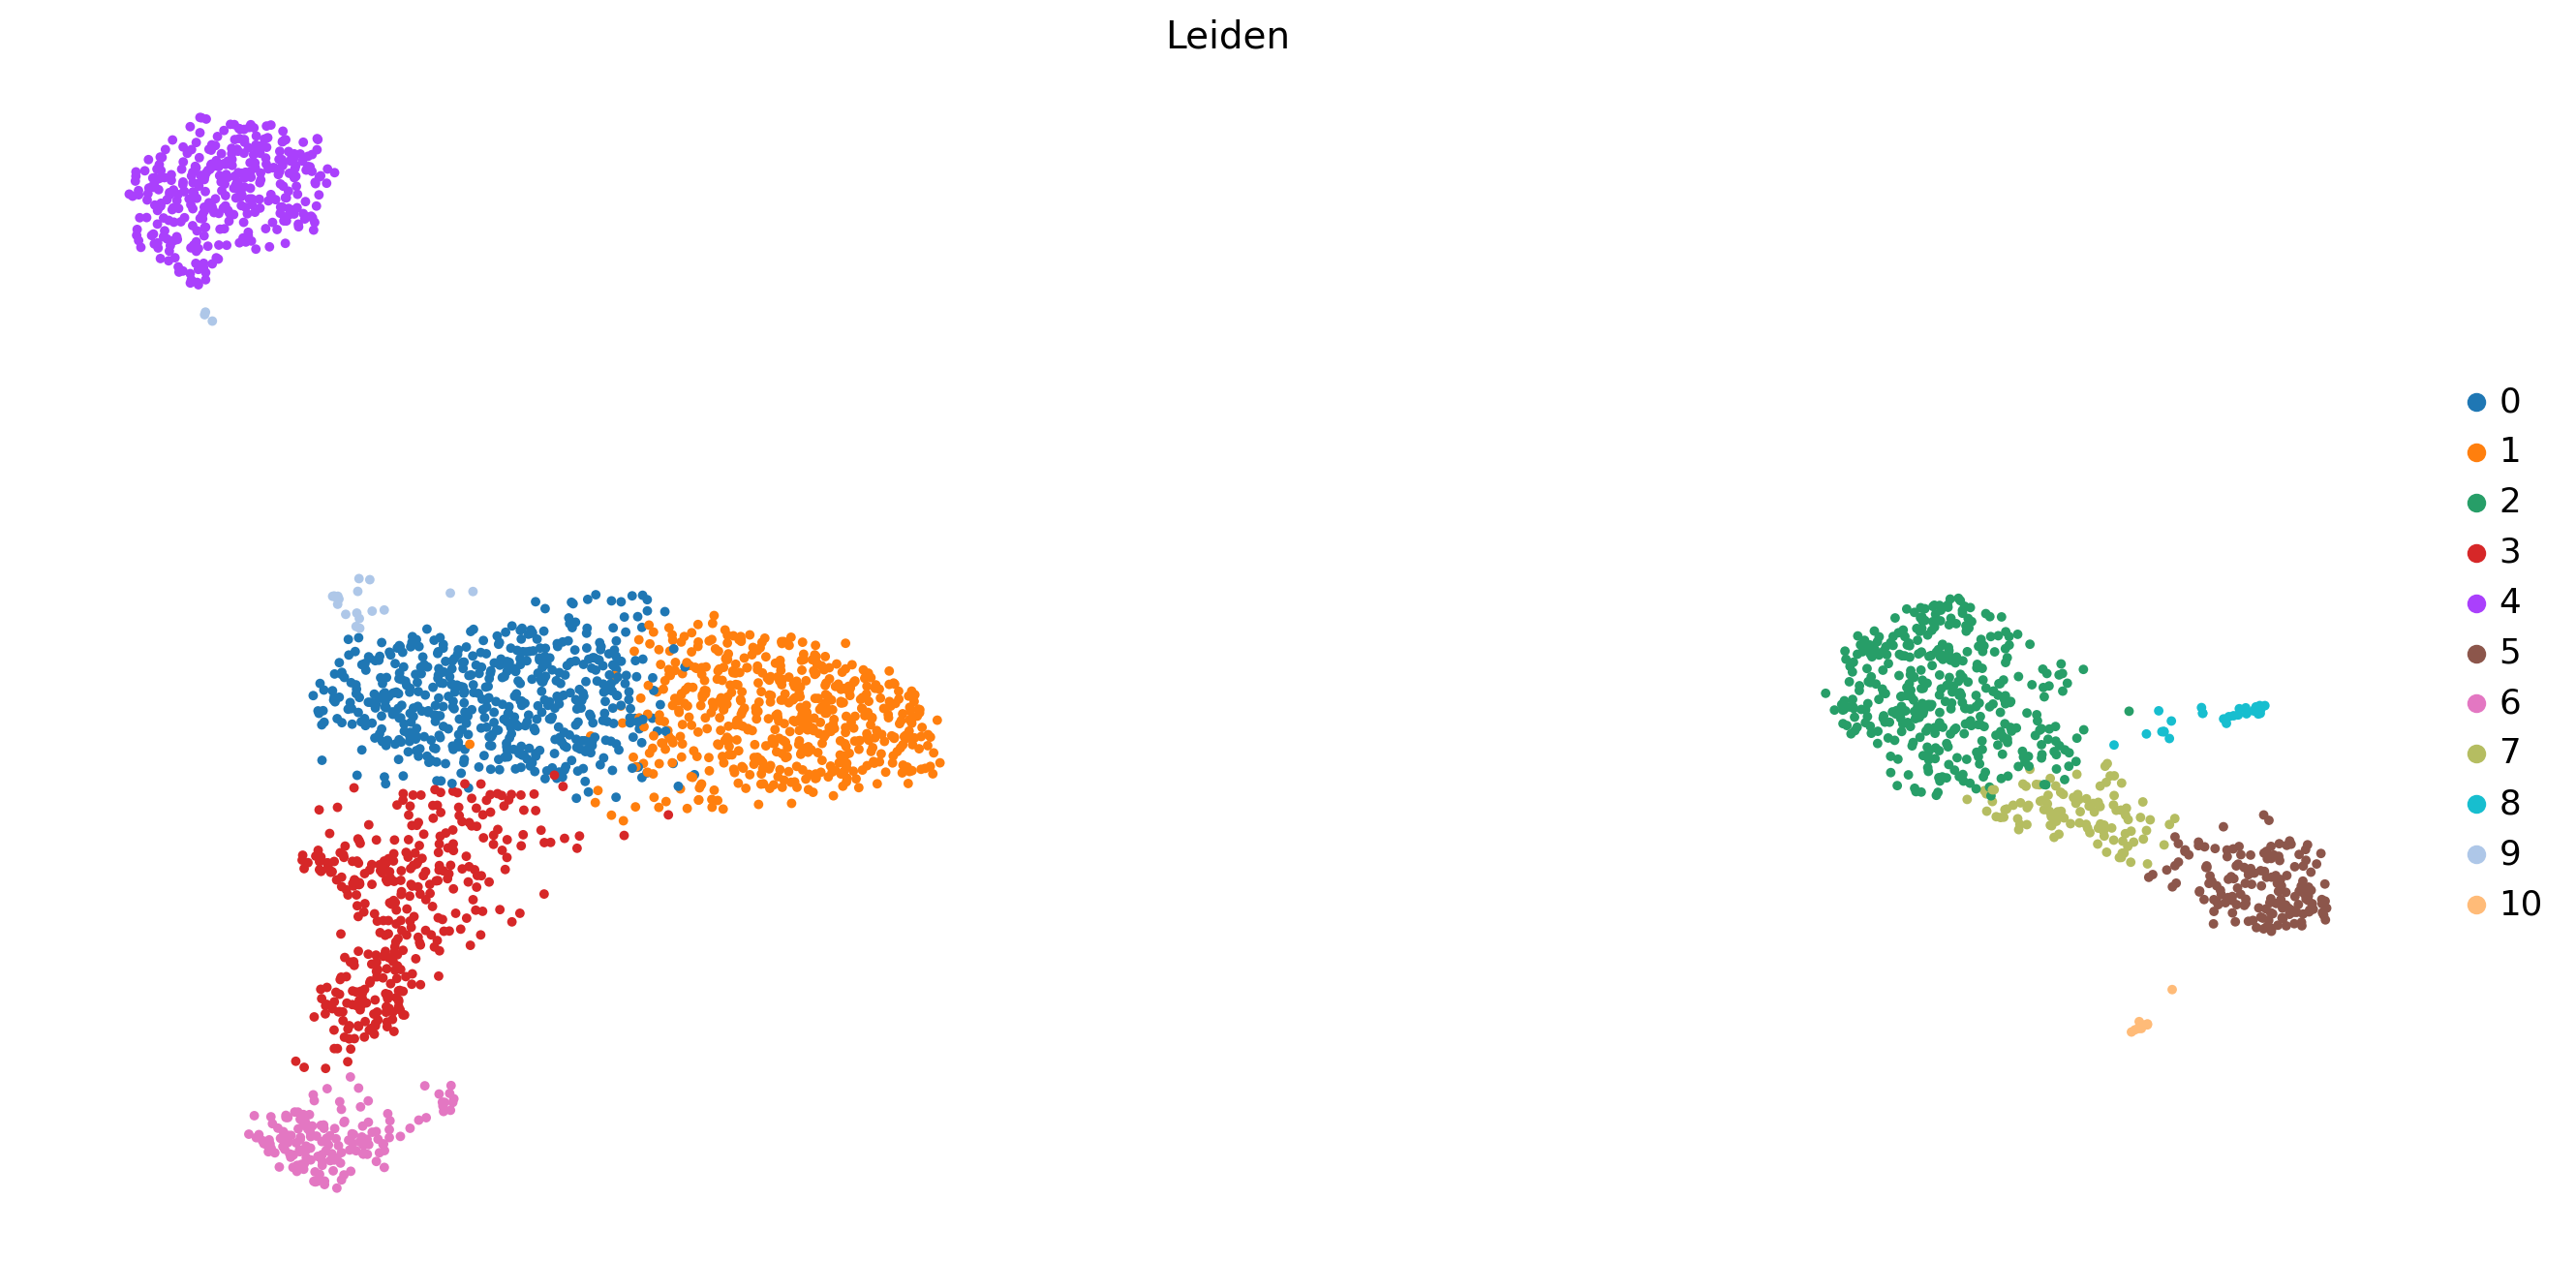

In [ ]:
sc.pl.umap(adata, color='leiden_1.0',  size=50,
           title="Leiden")

# Очевидная идея - посмотреть на саммые экспрессируемые гены каждого кластера и попарно сравнить: кластер - кластер, кластер - все остальные клетки

---
## 1. Что значит маркер кластера?

Пусть $x_{cg}$ — лог-нормализованная экспрессия гена $g$ в клетке $c$.

Для каждого кластера $A$ и гена $g$ сравниваем две группы:

- $A$: клетки данного кластера;
- $B$: все остальные клетки (`reference='rest'`) или клетки заранее выбранного второго кластера.

**Нулевая гипотеза рангового теста** — распределения экспрессии в группах одинаковы:

$$H_0:\ F_{g,A}(x)=F_{g,B}(x).$$

Альтернативная гипотеза (в реализации двустороннего теста) — распределения различаются. Часто нас интересуют гены с **положительным эффектом** и экспрессией у значительной доли клеток внутри кластера.

---
### 1.1. Wilcoxon rank-sum

**Критерий Уилкоксона для независимых выборок** не требует нормальности исходных значений, а использует **ранги** наблюдений

Для $n_A$ и $n_B$ наблюдений суммарная ранговая сумма внутри группы $A$ — $R_A$. Статистика:

$$U_A = R_A - \frac{n_A(n_A+1)}{2}.$$

При непрерывных распределениях $U_A$ можно понимать как число пар $(a,b)$ с $a>b$ с учётом половины пар с равными значениями. При $H_0$ ожидается $E(U_A)=n_A n_B/2$.


Если у нас 3 клетки против 3:
- $U_A=4$ — близко к ожидаемому 4,5.
- $U_A=0$ — все значения A меньше всех значений B.
- $U_A=9$ — все значения A больше всех значений B.

In [ ]:
from scipy.sparse import issparse
from scipy.stats import rankdata, mannwhitneyu

group_col = "leiden_1.0"
gene = "NKG7"

clusters = adata.obs[group_col].astype(str)
cluster_a, cluster_b = "0","3"


# Функция получения экспрессии одного гена
def get_expression(cluster):
    mask = (clusters == cluster).to_numpy()
    x = adata[mask, gene].X

    if issparse(x):
        return x.toarray().ravel()

    return np.asarray(x).ravel()

A = get_expression(cluster_a)
B = get_expression(cluster_b)

print(f"Ген: {gene}")
print(f"Кластер A ({cluster_a}): {len(A)} клеток")
print(f"Кластер B ({cluster_b}): {len(B)} клеток")
print(f"Первые значения A: {A[:10]}")
print(f"Первые значения B: {B[:10]}")

Ген: NKG7
Кластер A (0): 553 клеток
Кластер B (3): 347 клеток
Первые значения A: [0.        0.        0.        0.        0.        1.8993901 0.
 1.3690697 0.        0.       ]
Первые значения B: [0.        3.1775749 2.2874265 2.1796417 3.2982152 0.        3.553674
 3.1240873 0.        4.314828 ]


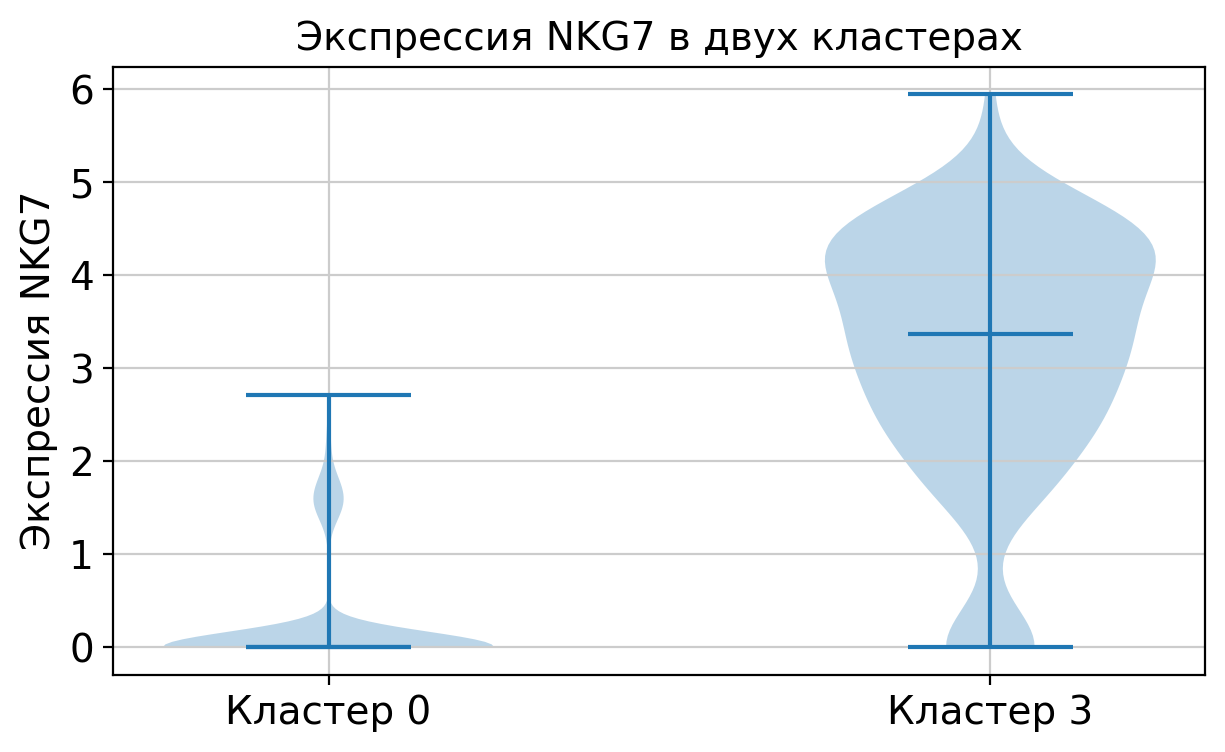

In [ ]:
plt.figure(figsize=(7, 4))

plt.violinplot([A, B], showmedians=True)

plt.xticks([1, 2], ["Кластер 0", "Кластер 3"])
plt.ylabel("Экспрессия NKG7")
plt.title("Экспрессия NKG7 в двух кластерах")

plt.show()

---
### 1.2. Что получаем?

- `scores` для `method='wilcoxon'`: подписанная стандартизованная статистика рангового теста (не fold change).
- `pvals`: вероятность получить столь же экстремальную или более экстремальную статистику **при выполнении $H_0$**.
- `pvals_adj`: скорректированное значение при множественном тестировании.
- `logfoldchanges`: логарифм отношения оценённых уровней экспрессии, где знак отражает направление.
- `pct_nz_group` и `pct_nz_reference` (если доступны): доля клеток с ненулевой экспрессией в группе и в контроле.

$$\mathrm{log_2FC}=\log_2\frac{\mu_A}{\mu_B}, \quad \mu_A,\mu_B>0.$$

---
### 1.3. Поправка на множественные сравнения: Benjamini–Hochberg

Если мы тестируем 12 000 генов, при верной нулевой гипотезе и пороге FDR (это не p-value) 0.05 в среднем получим $12\,000\cdot 0.05=600$ ложноположительных результатов.

Метод BH контролирует **ожидаемую долю ложных отклонений среди отклонённых гипотез (FDR)** при соответствующих условиях. Мы сначала выбираем допустимый уровень FDR (например, 5%), а затем BH находит, какие гены можно объявить статистически значимыми, чтобы оставлять FDR на этом уровне. Можем получить для каждого гена соответствующую границу p-value чтобы он проходил границу FDR.

Затем мы хотим проверять на один заданный уровень FDR, а получить для каждого гена минимально допустимый FDR, тогда мы упорядовачиваем все p-value по своему значению и умножаем на коэффициент отражающий его ранговое положение относительно всех p-value. Затем идём от наименьшего и проверяем что у нас сохраняется неубывание по новым значениям. Если это правильно нарушается на шаге i то берем минимум между $i-1$ и $i$.

Упорядочим $p_{(1)}\le\ldots\le p_{(m)}$. Для ранга $i$ сначала считаем $p_{(i)}m/i$, затем обеспечиваем неубывание скорректированных значений по рангу через минимум по всем $j\ge i$, ограничивая результат единицей:

$$q_{(i)} = \min\left(1,\min_{j\ge i}\frac{m\,p_{(j)}}{j}\right).$$

### 1.4. Находим маркеры в клетках

**Важно: какое множество генов тестировать?** После отбора HVG в семинаре 1 **гены не были удалены**, лишь помечены `adata.var['highly_variable']`. Поэтому `adata.X` содержит и HVG, и остальные гены, что позволяет исследовать известные маркеры, не попавшие в HVG.

Расчёт `sc.tl.rank_genes_groups` ожидает **логарифмированные данные**, поэтому указываем `use_raw=False`, `layer=None`. `tie_correct=True` учитывает одинаковые значения для поправки дисперсии ранговой статистики.

In [ ]:
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden_1.0',
    method="wilcoxon",
    reference="rest",
    use_raw=False,
    layer=None,
    tie_correct=True,
    corr_method="benjamini-hochberg",
    pts=True, # вычисляет долю клеток, в которых экспрессируется каждый ген
    key_added='wilcoxon',
)

ranking genes


/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (


    finished (0:00:44)


/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:358: RuntimeWarning: invalid value encountered in divide
  scores[group_index, :] = (
/home/bkarpovich/.conda/envs/chicken_env/lib/pytho

In [ ]:
clusters = list(adata.obs['leiden_1.0'].cat.categories)
first_cluster = clusters[0]
markers_example = sc.get.rank_genes_groups_df(adata, group=first_cluster, key='wilcoxon')

In [ ]:
print(f"Кластер {first_cluster}; строк: {len(markers_example)}")
display(markers_example.head(15))

Кластер 0; строк: 13714


,names,scores,logfoldchanges,pvals,pvals_adj,pct_nz_group,pct_nz_reference
0,LTB,23.282074,2.577841,6.735695e-120,9.237332e-116,0.985533,0.629257
1,IL32,20.799780,2.478875,4.347950e-96,2.981389e-92,0.933092,0.451319
2,IL7R,20.685240,2.427370,4.704312e-95,2.150498e-91,0.766727,0.305995
3,LDHB,19.324514,1.869246,3.341162e-83,1.145517e-79,0.945750,0.603357
4,CD3D,18.301039,2.142672,8.118718e-75,2.226802e-71,0.900542,0.419185
5,AQP3,18.214695,2.622822,3.946100e-74,9.019470e-71,0.424955,0.098801
6,TNFRSF4,17.268358,3.846911,8.142729e-67,1.240771e-63,0.211573,0.017746
7,TPT1,17.032158,0.706515,4.742340e-65,6.503645e-62,0.996383,0.983213
8,CD40LG,16.717585,2.796053,9.759444e-63,1.115342e-59,0.300181,0.052758
9,CD2,15.932926,1.953737,3.744189e-57,3.209238e-54,0.607595,0.241727


    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden_1.0']`


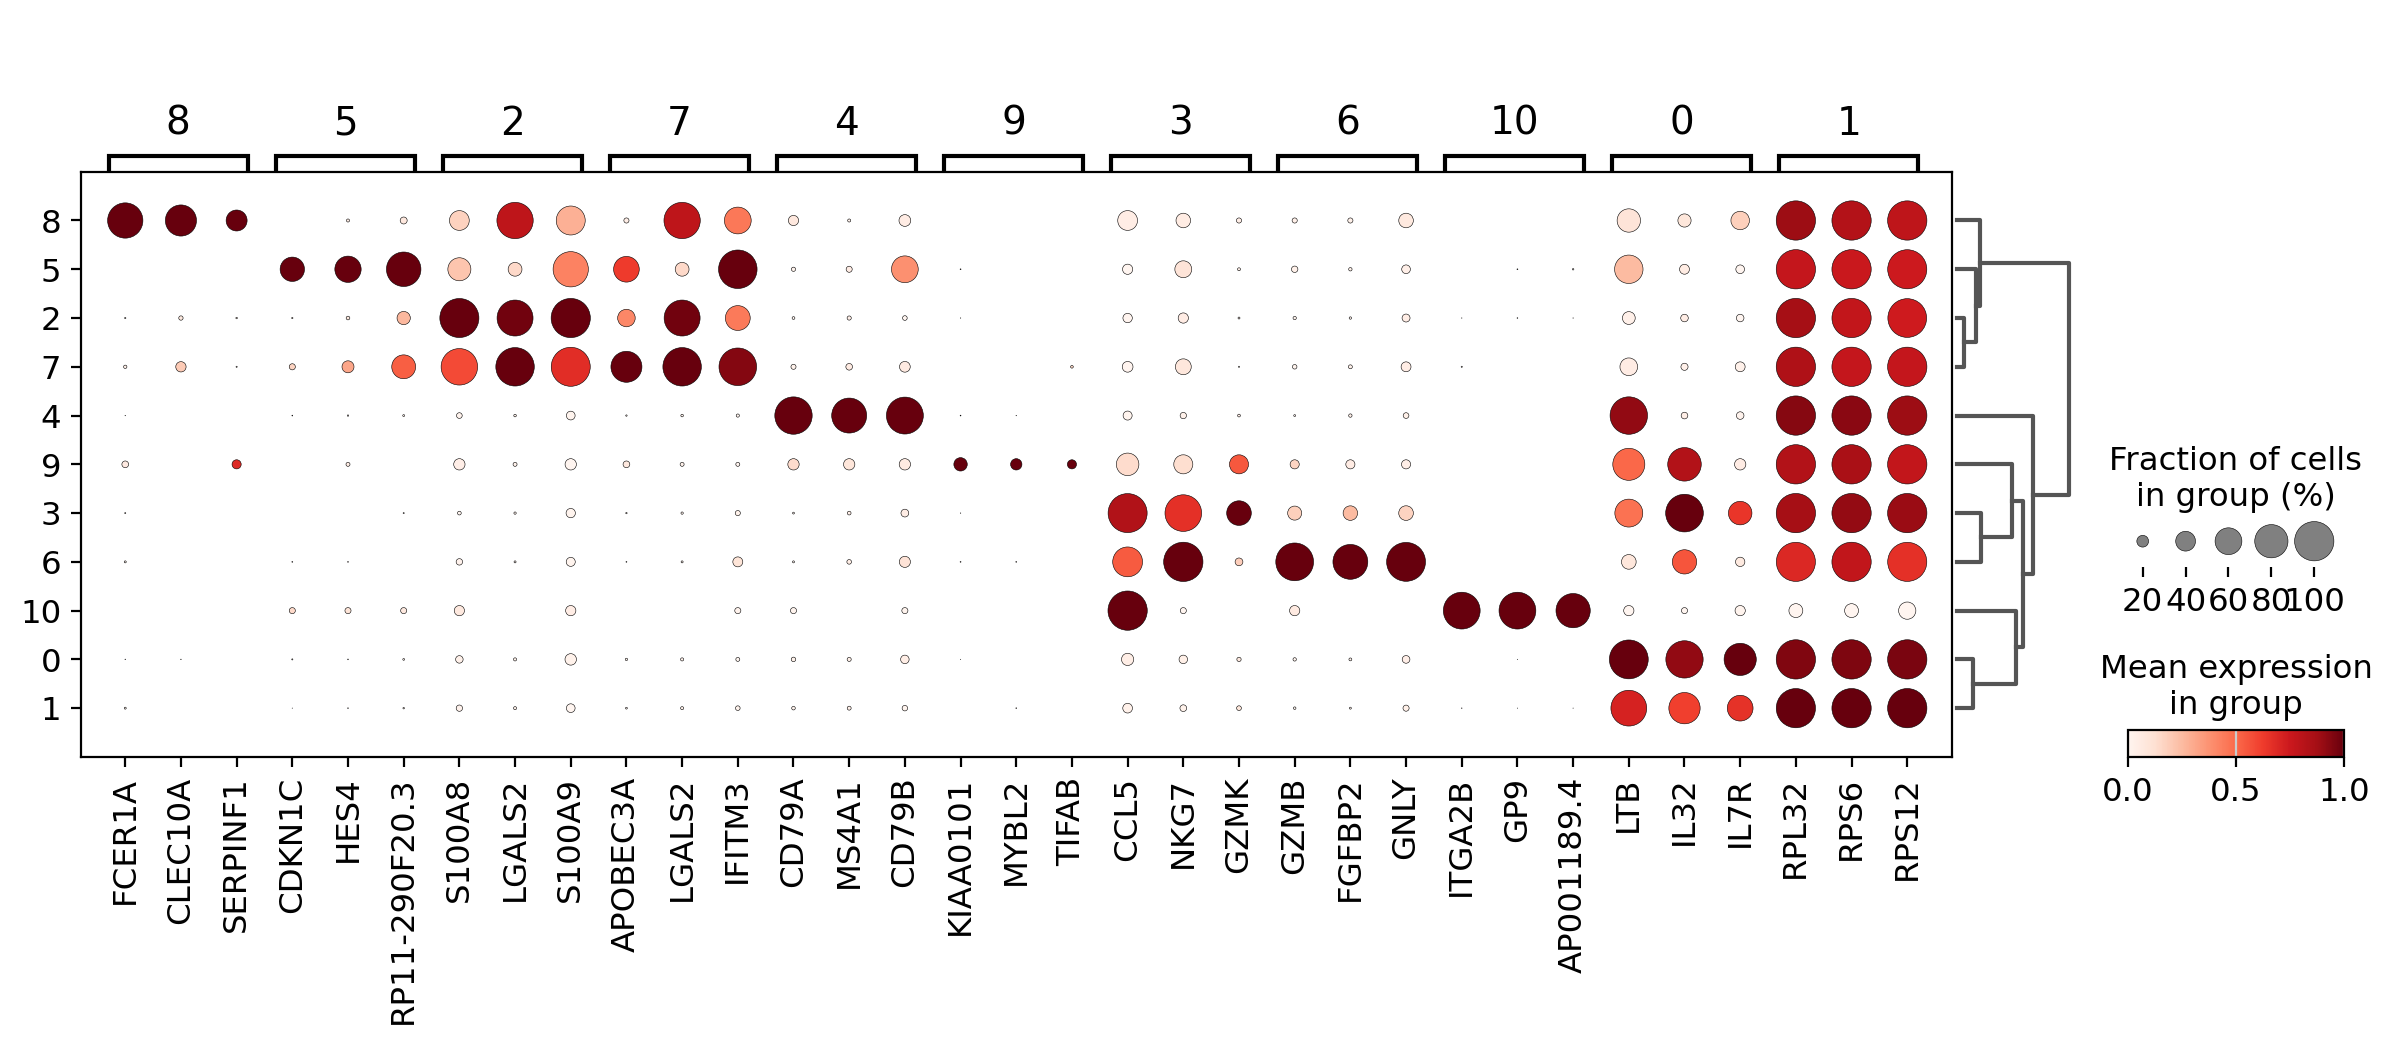

In [ ]:
# Визуализируем по 3 наиболее высокоранжированных гена на кластер.
sc.pl.rank_genes_groups_dotplot(
    adata,
    key='wilcoxon',
    groupby='leiden_1.0',
    n_genes=3,
    use_raw=False,
    standard_scale="var",
)

### 1.6. Сравнение «один против всех» и «один против одного»

`reference='rest'` отвечает на вопрос «чем кластер A отличается от смеси всех остальных?». Но если два соседних T-клеточных кластера похожи, для их сравнения лучше **A vs B**, а не A vs rest.

In [ ]:
group_A, group_B = "0","3"
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden_1.0',
    groups=[group_A],
    reference=group_B,
    method="wilcoxon",
    tie_correct=True,
    use_raw=False,
    key_added="pairwise_0_3",
)

ranking genes
    finished (0:00:01)


/home/bkarpovich/.conda/envs/chicken_env/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:320: RuntimeWarning: invalid value encountered in divide
  scores = (


In [ ]:
display(sc.get.rank_genes_groups_df(
    adata, group=group_A, key="pairwise_0_3"
).head(10))

print(f"Вычислено сравнение: cluster {group_A} vs cluster {group_B}")

,names,scores,logfoldchanges,pvals,pvals_adj
0,LTB,15.570868,2.451982,1.148398e-54,1.968642e-51
1,VIM,12.210079,1.372892,2.746232e-34,2.510788e-31
2,TPT1,11.931991,0.572724,8.062242e-33,6.142533e-30
3,LDHB,11.851615,1.382455,2.110839e-32,1.447402e-29
4,RPL32,11.696859,0.465427,1.322589e-31,8.637134e-29
5,TMSB10,11.047319,0.700616,2.258575e-28,1.407914e-25
6,RPL11,11.023608,0.408228,2.940305e-28,1.753189e-25
7,JUNB,10.349001,1.221219,4.228759e-25,2.230508e-22
8,RPL36,10.028109,0.760316,1.146930e-23,5.243001e-21
9,RPS25,9.917639,0.500961,3.489123e-23,1.495307e-20


Вычислено сравнение: cluster 0 vs cluster 3


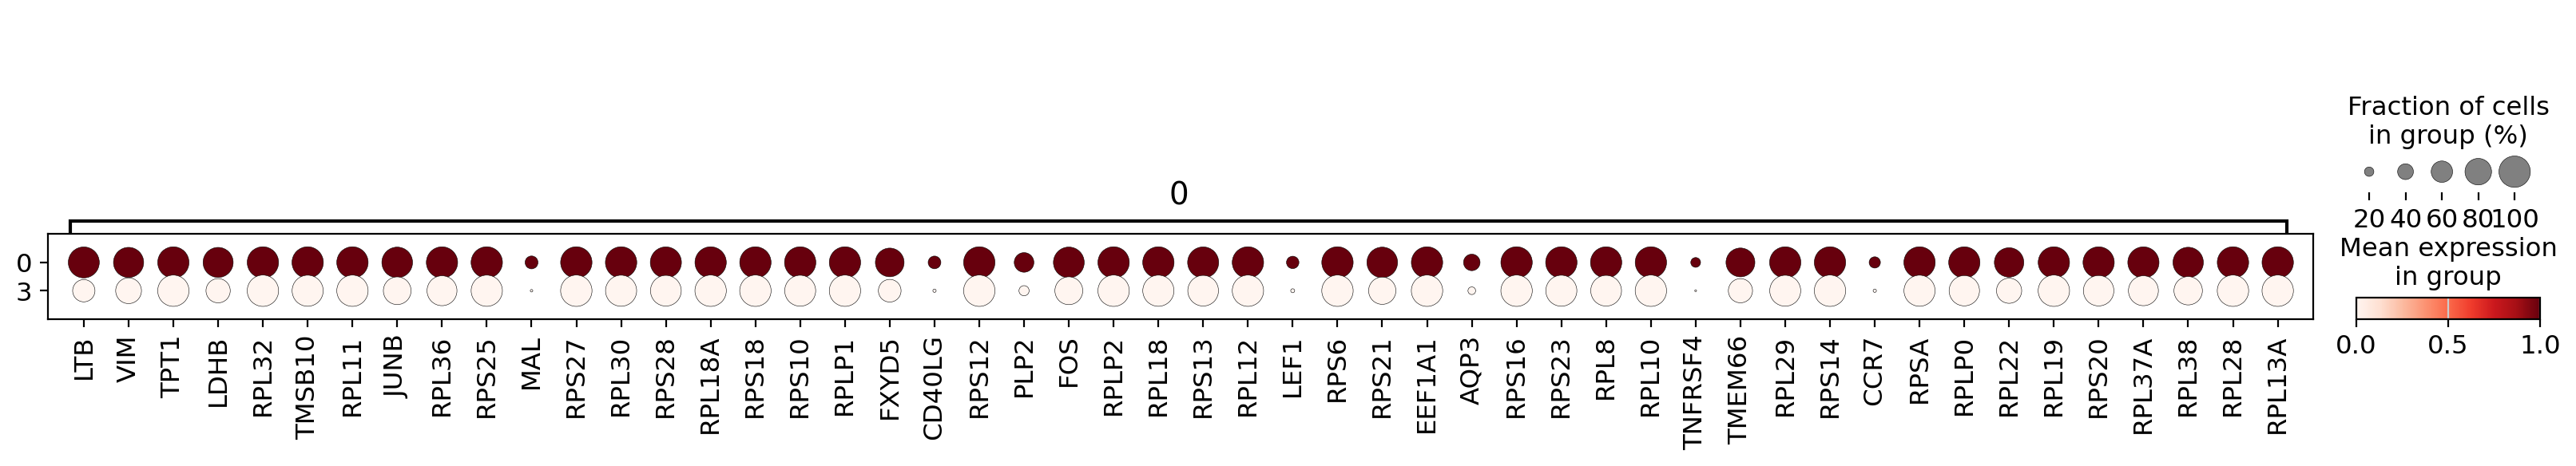

In [ ]:
adata_pair = adata[
    adata.obs["leiden_1.0"].isin(["0", "3"])
].copy()

adata_pair.obs["leiden_1.0"] = (
    adata_pair.obs["leiden_1.0"]
    .cat.remove_unused_categories()
)
sc.pl.rank_genes_groups_dotplot(
    adata_pair,
    key="pairwise_0_3",
    groups=["0"],
    groupby="leiden_1.0",
    n_genes=50,
    use_raw=False,
    standard_scale="var",
    dendrogram=False,
)

---
## 2. Ручная аннотация клеточных кластеров

В основе ручной аннотации — сопоставление **набора согласованных маркеров** с биологическими знаниями.

| Возможная группа клеток | Проверяемые гены | Ограничения |
|---|---|---|
| T-лимфоциты | `CD3D`, `CD3E`, `TRAC` | T-клеточные типы можно делить дальше |
| CD4 T / наивные T | `IL7R`, `CCR7`, `LTB`, `CD4` | `IL7R`/`CCR7` не являются исключительно CD4-маркерами |
| CD8 / цитотоксические T | `CD8A`, `CD8B`, `CCL5`, `GZMK` | Пересечение с NK и активированными T-клетками |
| NK-клетки | `NKG7`, `GNLY`, `KLRD1`, `PRF1` | `NKG7` и `PRF1` встречаются в цитотоксических T |
| B-лимфоциты | `MS4A1`, `CD79A`, `CD79B` | Популяции плазмобластов могут отличаться |
| CD14+ моноциты | `LYZ`, `LST1`, `S100A8`, `S100A9`, `CD14` | Гранулоцитарные маркеры тоже могут встречаться |
| FCGR3A+ моноциты | `FCGR3A`, `LST1`, `MS4A7` | `FCGR3A` бывает и в NK |
| Дендритные клетки | `FCER1A`, `CD1C`, `CST3` | `CST3` не специфичен для DC |
| Тромбоциты/мегакариоцитарные элементы | `PPBP`, `PF4` | Могут отражать активированные тромбоциты или контаминацию |

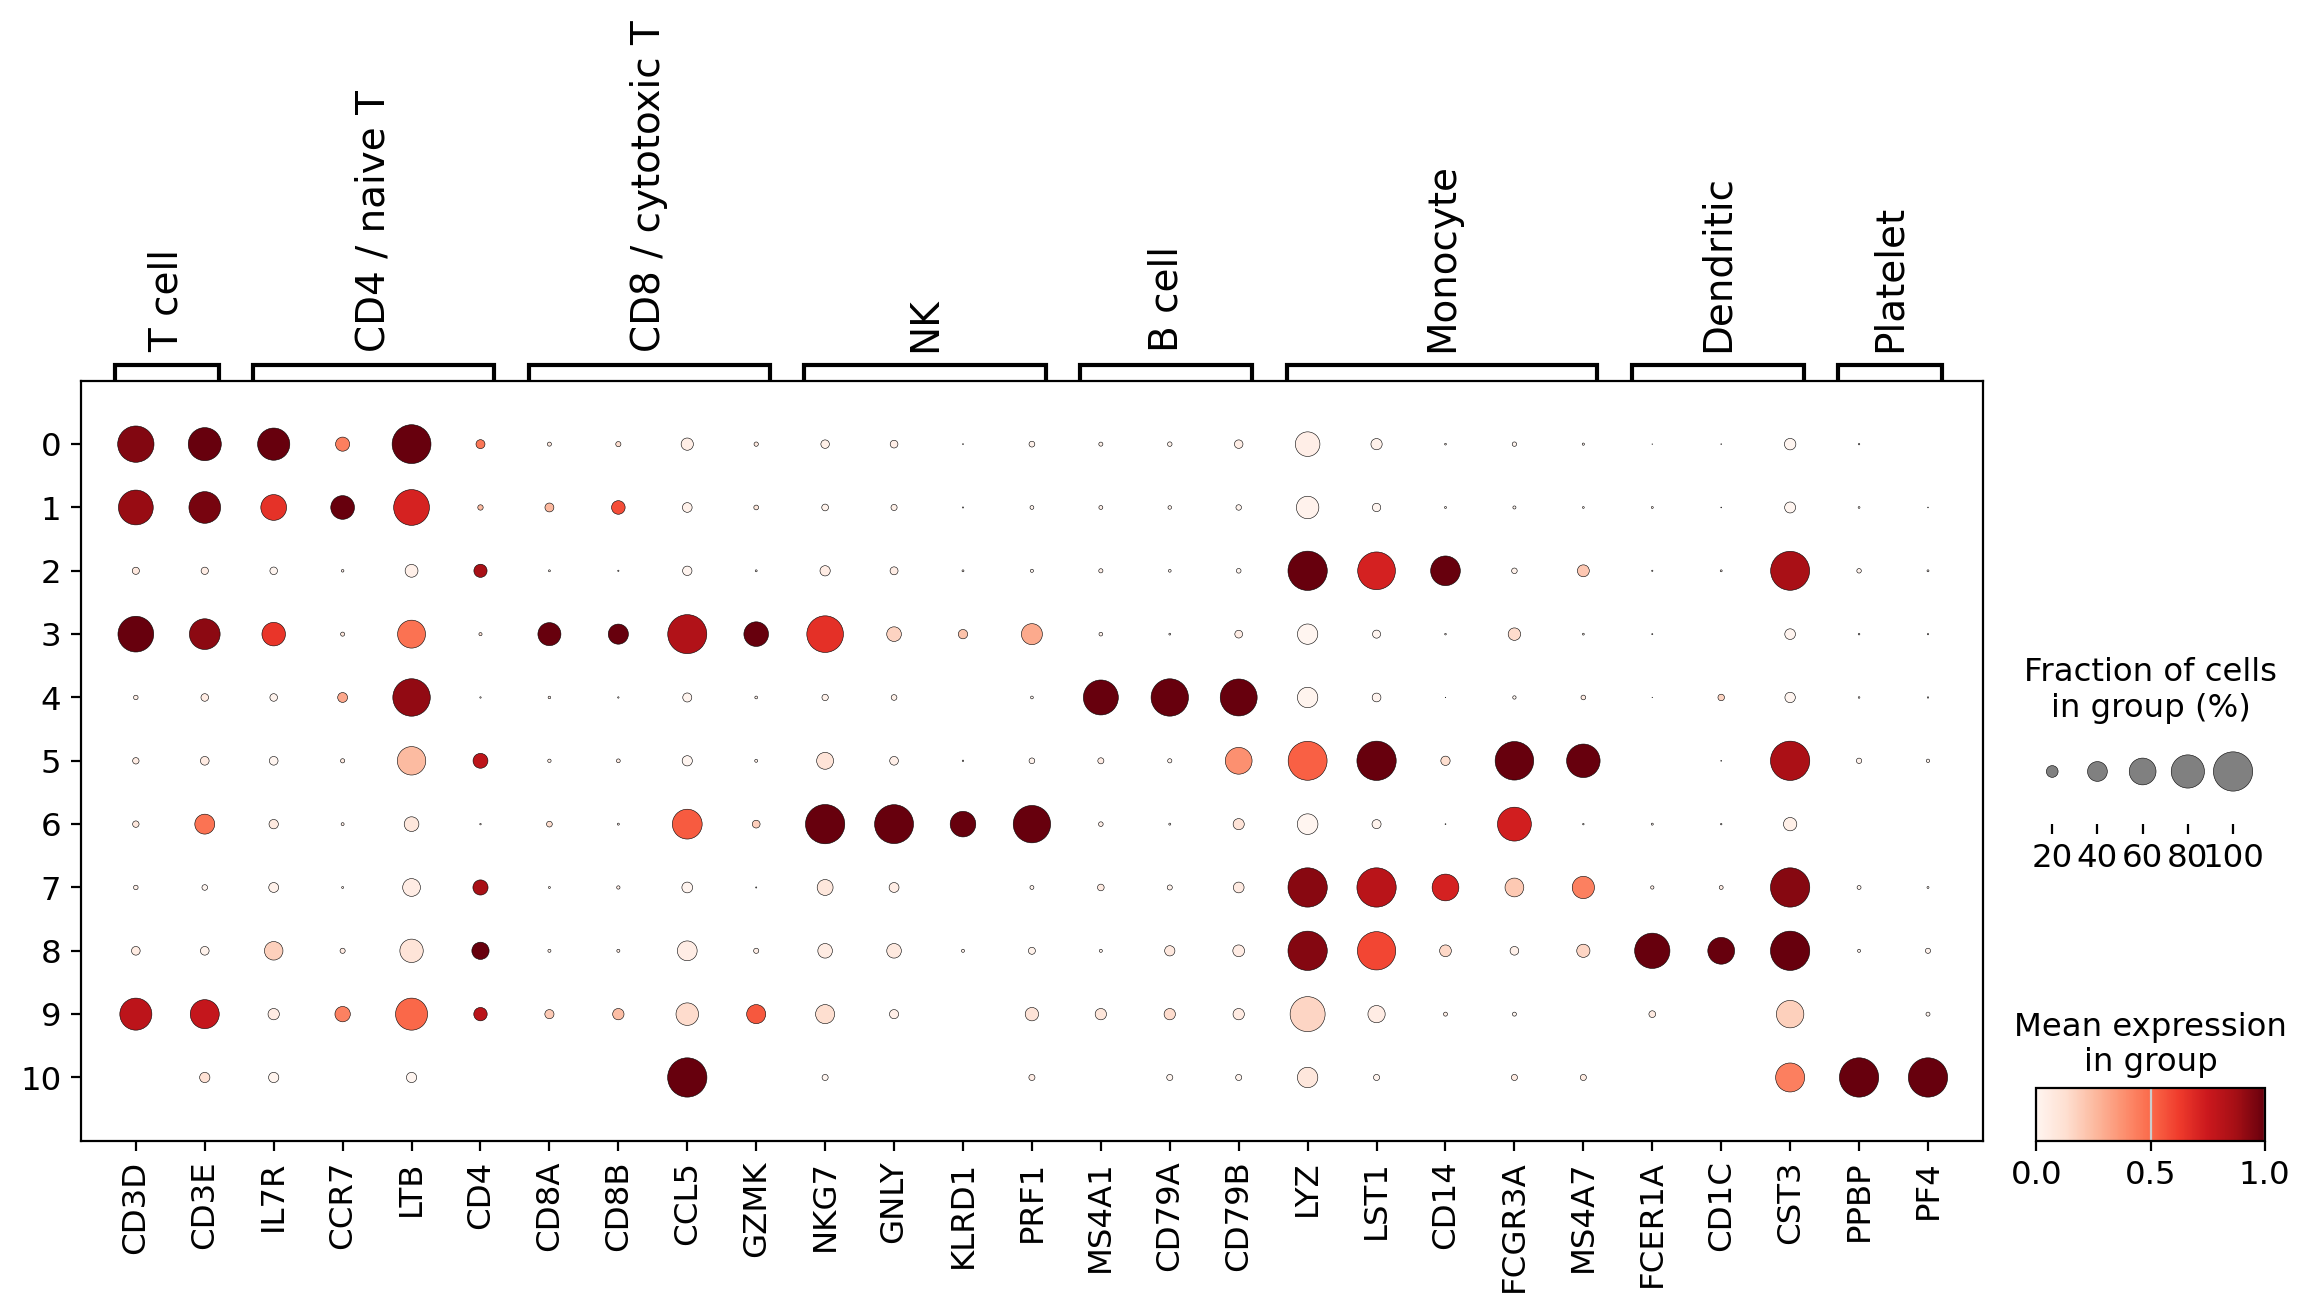

In [ ]:
MARKERS = {
    "T cell": ["CD3D", "CD3E", "TRAC"],
    "CD4 / naive T": ["IL7R", "CCR7", "LTB", "CD4"],
    "CD8 / cytotoxic T": ["CD8A", "CD8B", "CCL5", "GZMK"],
    "NK": ["NKG7", "GNLY", "KLRD1", "PRF1"],
    "B cell": ["MS4A1", "CD79A", "CD79B"],
    "Monocyte": ["LYZ", "LST1", "CD14", "FCGR3A", "MS4A7"],
    "Dendritic": ["FCER1A", "CD1C", "CST3"],
    "Platelet": ["PPBP", "PF4"],
}
markers_present = {k: [g for g in genes if g in adata.var_names]
                   for k, genes in MARKERS.items()}
markers_present = {k: v for k, v in markers_present.items() if v}

sc.pl.dotplot(adata, var_names=markers_present, groupby='leiden_1.0',
              standard_scale="var", use_raw=False, figsize=(14, 5))

Как читать dotplot?

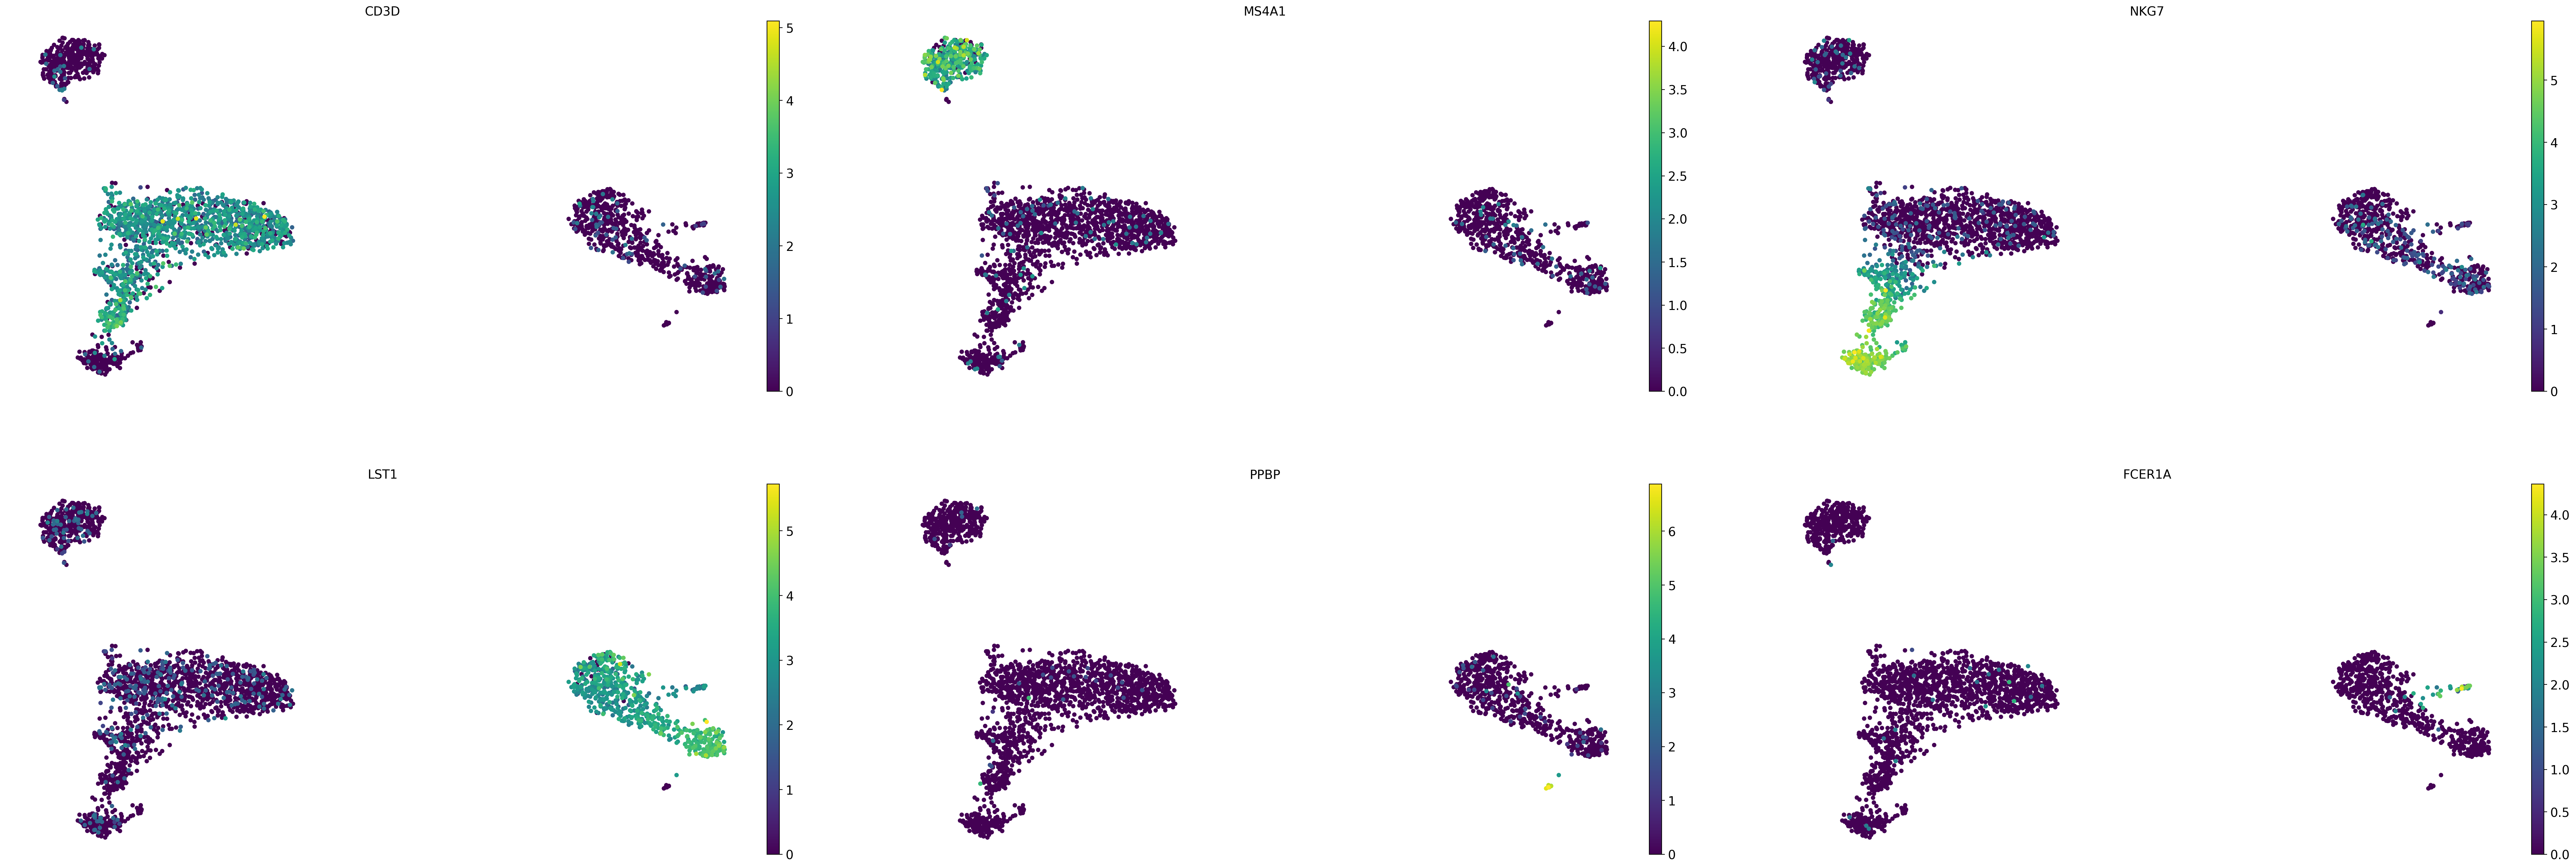

In [ ]:
example_genes = [g for g in ["CD3D", "MS4A1", "NKG7", "LST1", "PPBP", "FCER1A"] if g in adata.var_names]
sc.pl.umap(adata, color=example_genes, ncols=3, use_raw=False, size=100)

In [ ]:
manual_annotations = {str(c): "Unassigned" for c in clusters}

manual_annotations.update({
    "0": "CD4 T cell",
    "1": "Naive CD4 T cell",
    "2": "CD14+ Monocyte",
    "3": "CD8 Cytotoxic T cell",
    "4": "B cell",
    "5": "FCGR3A+ Monocyte",
    "6": "NK cell",
    "7": "CD14+ Monocyte",
    "8": "Dendritic cell (cDC)",
    "9": "T cell (memory-like)",
    "10": "Platelet",
})

unknown_keys = set(manual_annotations).difference(map(str, clusters))

adata.obs["manual_cell_type"] = pd.Categorical(
    adata.obs['leiden_1.0'].astype(str).map(manual_annotations).fillna("Unassigned")
)
print(pd.DataFrame({"cluster": list(manual_annotations),
                    "manual_cell_type": list(manual_annotations.values())}))

   cluster      manual_cell_type
0        0            CD4 T cell
1        1      Naive CD4 T cell
2        2        CD14+ Monocyte
3        3  CD8 Cytotoxic T cell
4        4                B cell
5        5      FCGR3A+ Monocyte
6        6               NK cell
7        7        CD14+ Monocyte
8        8  Dendritic cell (cDC)
9        9  T cell (memory-like)
10      10              Platelet


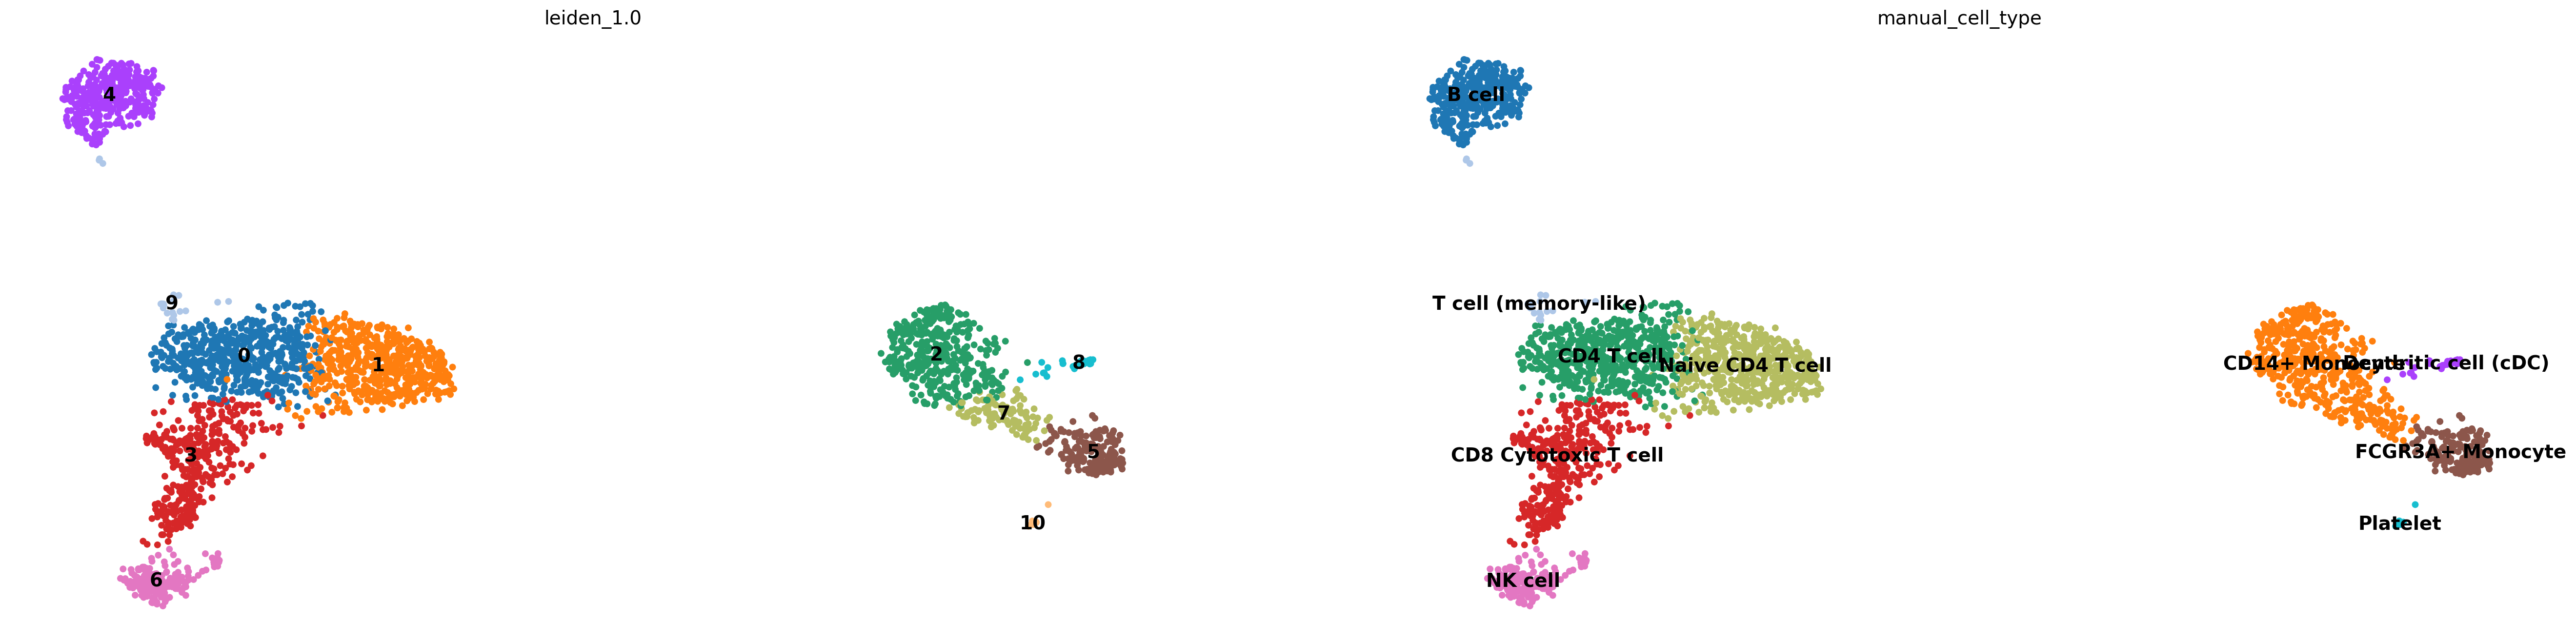

In [ ]:
sc.pl.umap(adata, color=['leiden_1.0', "manual_cell_type"], ncols=2, size=100, legend_loc="on data")

---
## 3. Автоматическая аннотация с CellTypist

Существуют уже размеченные аннотации, которые можно использовать. Попробуем использовать **обученную модель классификации** Celltypist.

На концептуальном уровне логистическая регрессия оценивает для класса $k$ линейную функцию признаков:

$$z_k = b_k + \sum_{g=1}^{G} w_{kg}x_g.$$

Далее из оценок формируют прогноз класса (в упрощённой бинарной задаче $\sigma(z)=1/(1+e^{-z})$).

Модель обучена на **размеченном референсе**, поэтому перенос её предсказаний ограничен и зависит от похожести клеточных типов, биологических состояний, платформ и референса.

Модель `Immune_All_Low.pkl` предназначена для иммунных клеток. CellTypist ожидает `log1p`-нормализованную экспрессию с суммой 10 000 до логарифмирования и символы генов — именно тот формат, который мы получили в первом семинаре.

In [ ]:
HAS_CELLTYPIST = True

if importlib.util.find_spec("celltypist") is None:
    print("CellTypist не установлен. Установите его в sc_pbmc или пропустите раздел 3.")
else:
    try:
        import celltypist
        # Используем локальную модель при наличии — это удобно на сервере без интернета.
        try:
            model = celltypist.models.Model.load("Immune_All_Low.pkl")
            print("Используем локальную модель CellTypist")
        except Exception:
            print("Модель отсутствует локально; пробуем скачать...")
            celltypist.models.download_models(model="Immune_All_Low.pkl")
            model = celltypist.models.Model.load("Immune_All_Low.pkl")

        prediction = celltypist.annotate(adata.copy(), model=model,
                                       majority_voting=False)
        celltypist_table = prediction.predicted_labels.reindex(adata.obs_names)
        assert celltypist_table["predicted_labels"].notna().all(), "Потеряна часть клеток"
        adata.obs["celltypist"] = pd.Categorical(
            celltypist_table["predicted_labels"].astype(str).to_numpy()
        )
        if "conf_score" in celltypist_table:
            adata.obs["celltypist_confidence"] = (
                celltypist_table["conf_score"].astype(float).to_numpy()
            )
        HAS_CELLTYPIST = True
        print("Автоматическая аннотация готова:")
        display(adata.obs["celltypist"].value_counts().to_frame("cells"))
    except Exception as error:
        print("CellTypist пропущен:", type(error).__name__, str(error)[:300])
        print("Можно продолжать семинар с ручной аннотацией")

🔬 Input data has 2638 cells and 13714 genes
🔗 Matching reference genes in the model


Используем локальную модель CellTypist


🧬 4178 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


Автоматическая аннотация готова:


,cells
celltypist,
Tcm/Naive helper T cells,636
Classical monocytes,393
B cells,340
Non-classical monocytes,229
Tcm/Naive cytotoxic T cells,215
Tem/Effector helper T cells,188
CD16+ NK cells,149
Tem/Trm cytotoxic T cells,110
Regulatory T cells,103


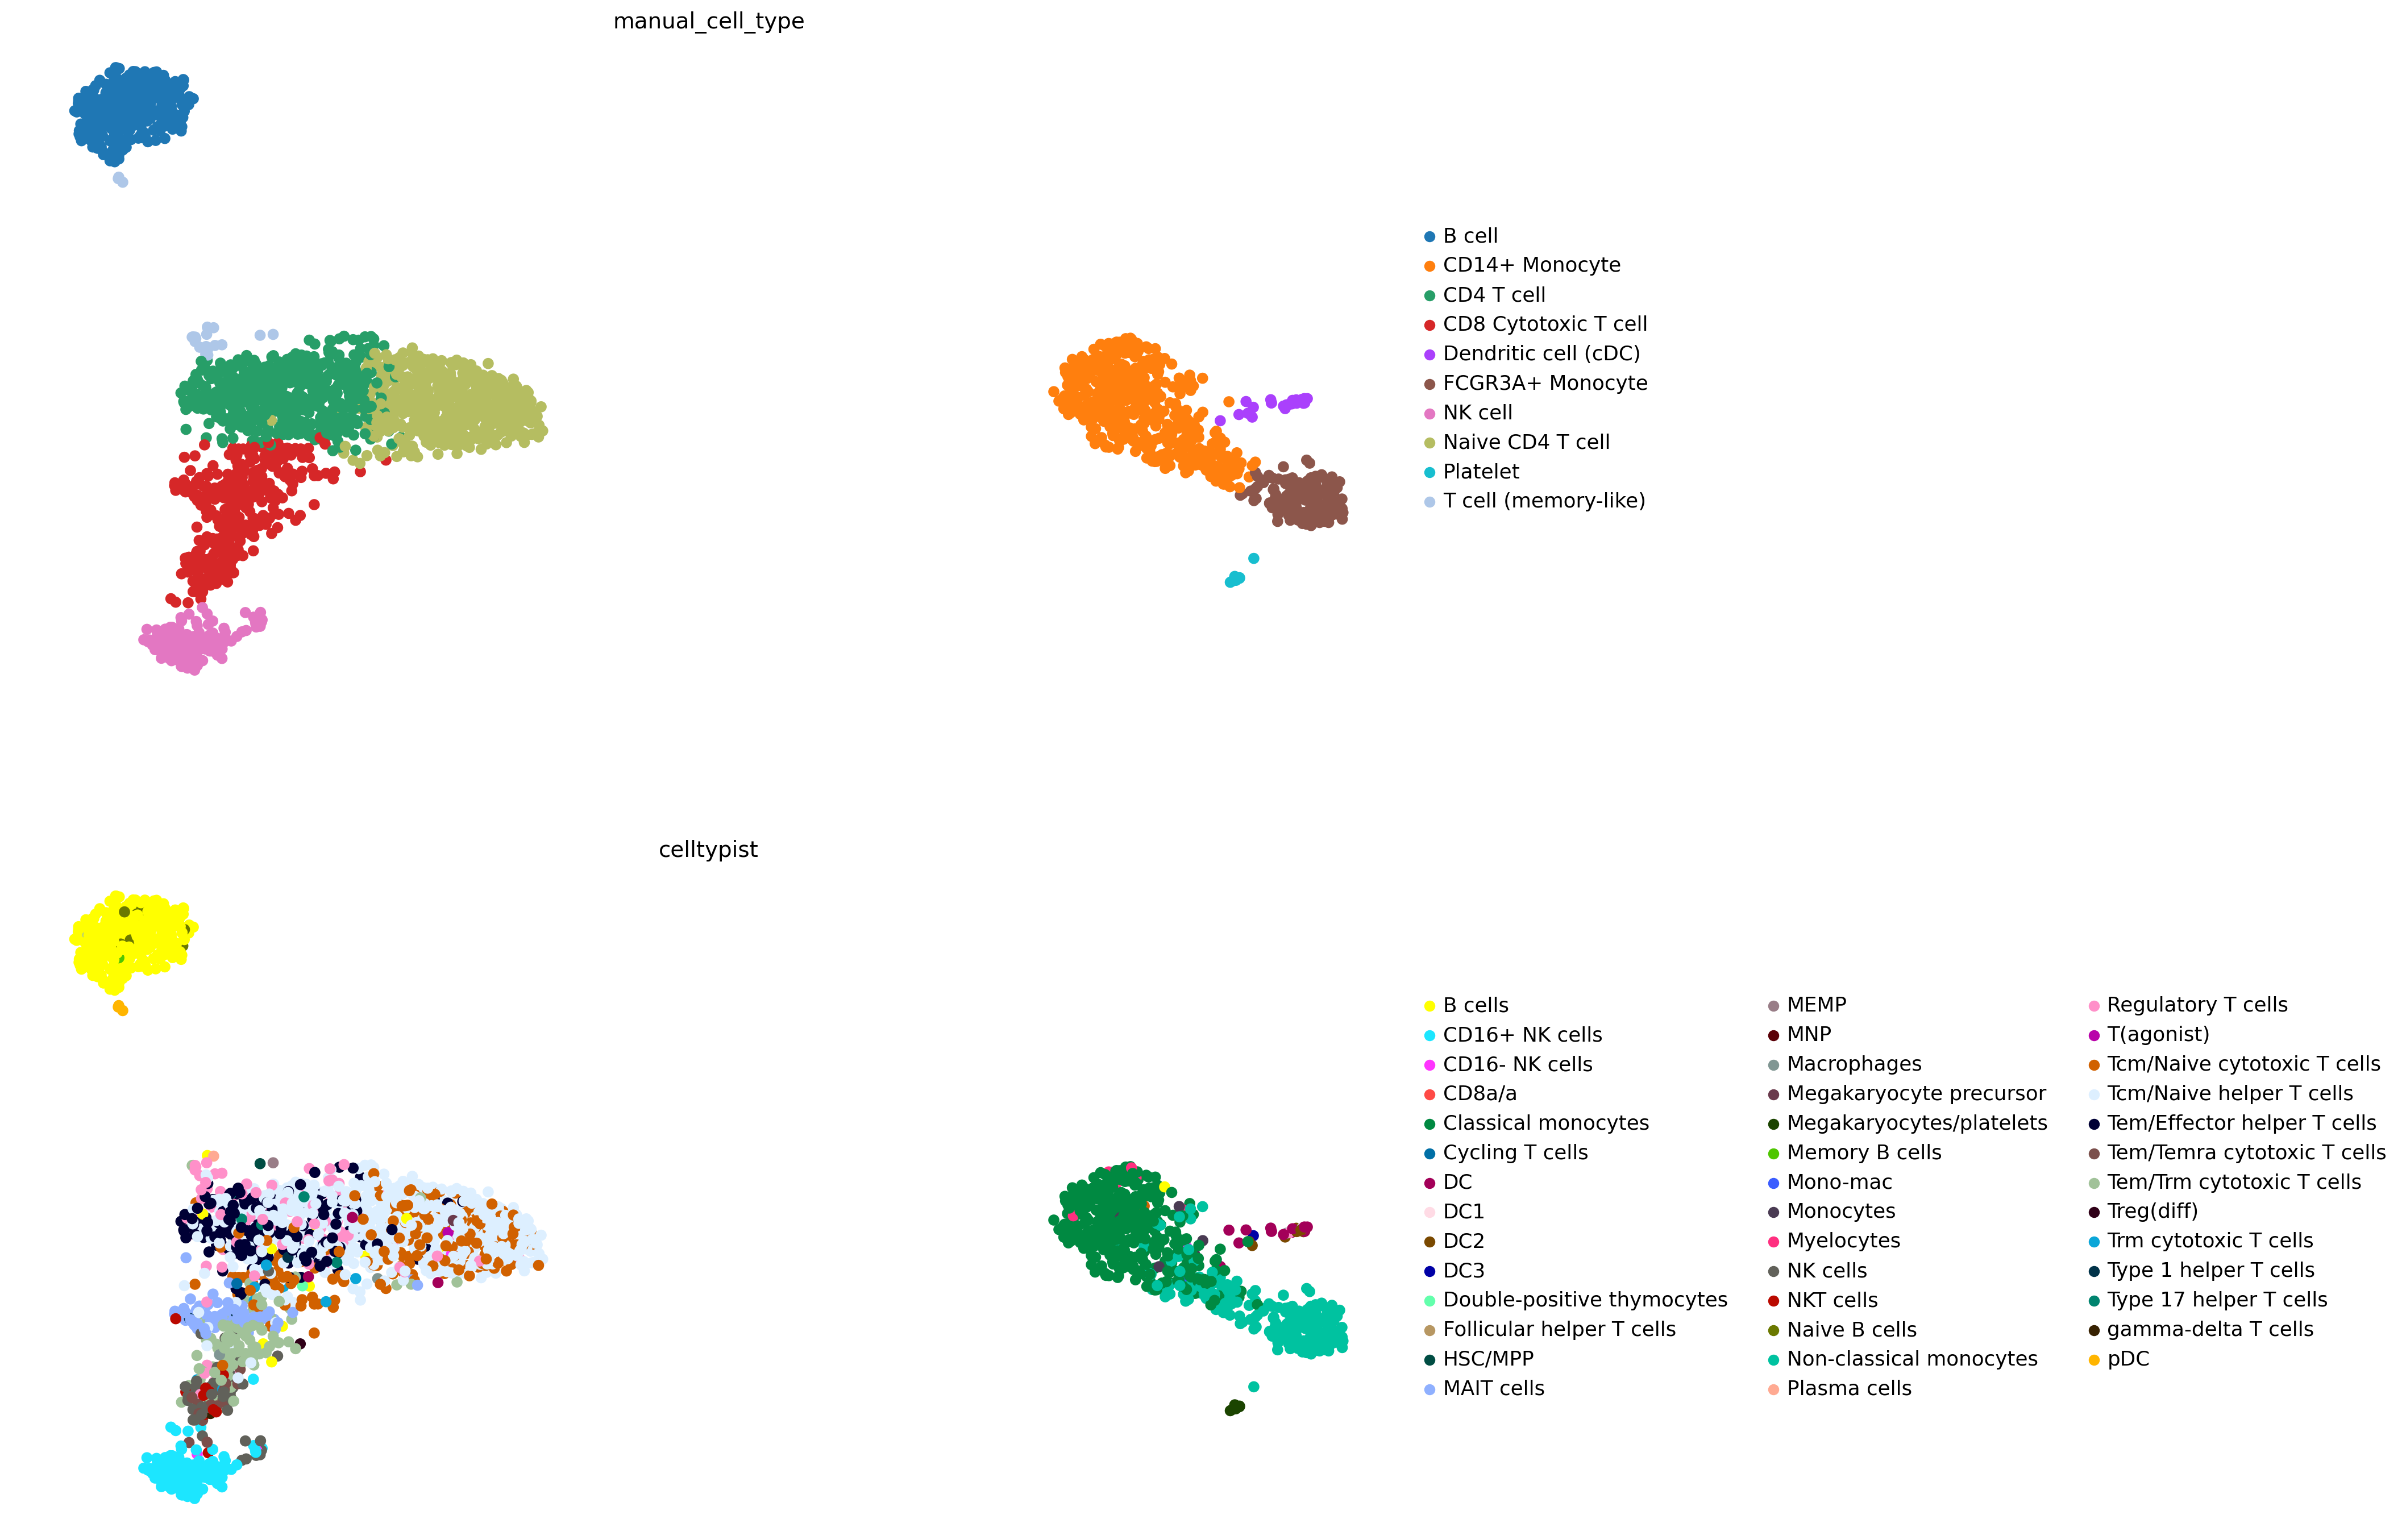

In [ ]:
sc.pl.umap(adata, color=["manual_cell_type", "celltypist"],
           ncols=1, size=200)

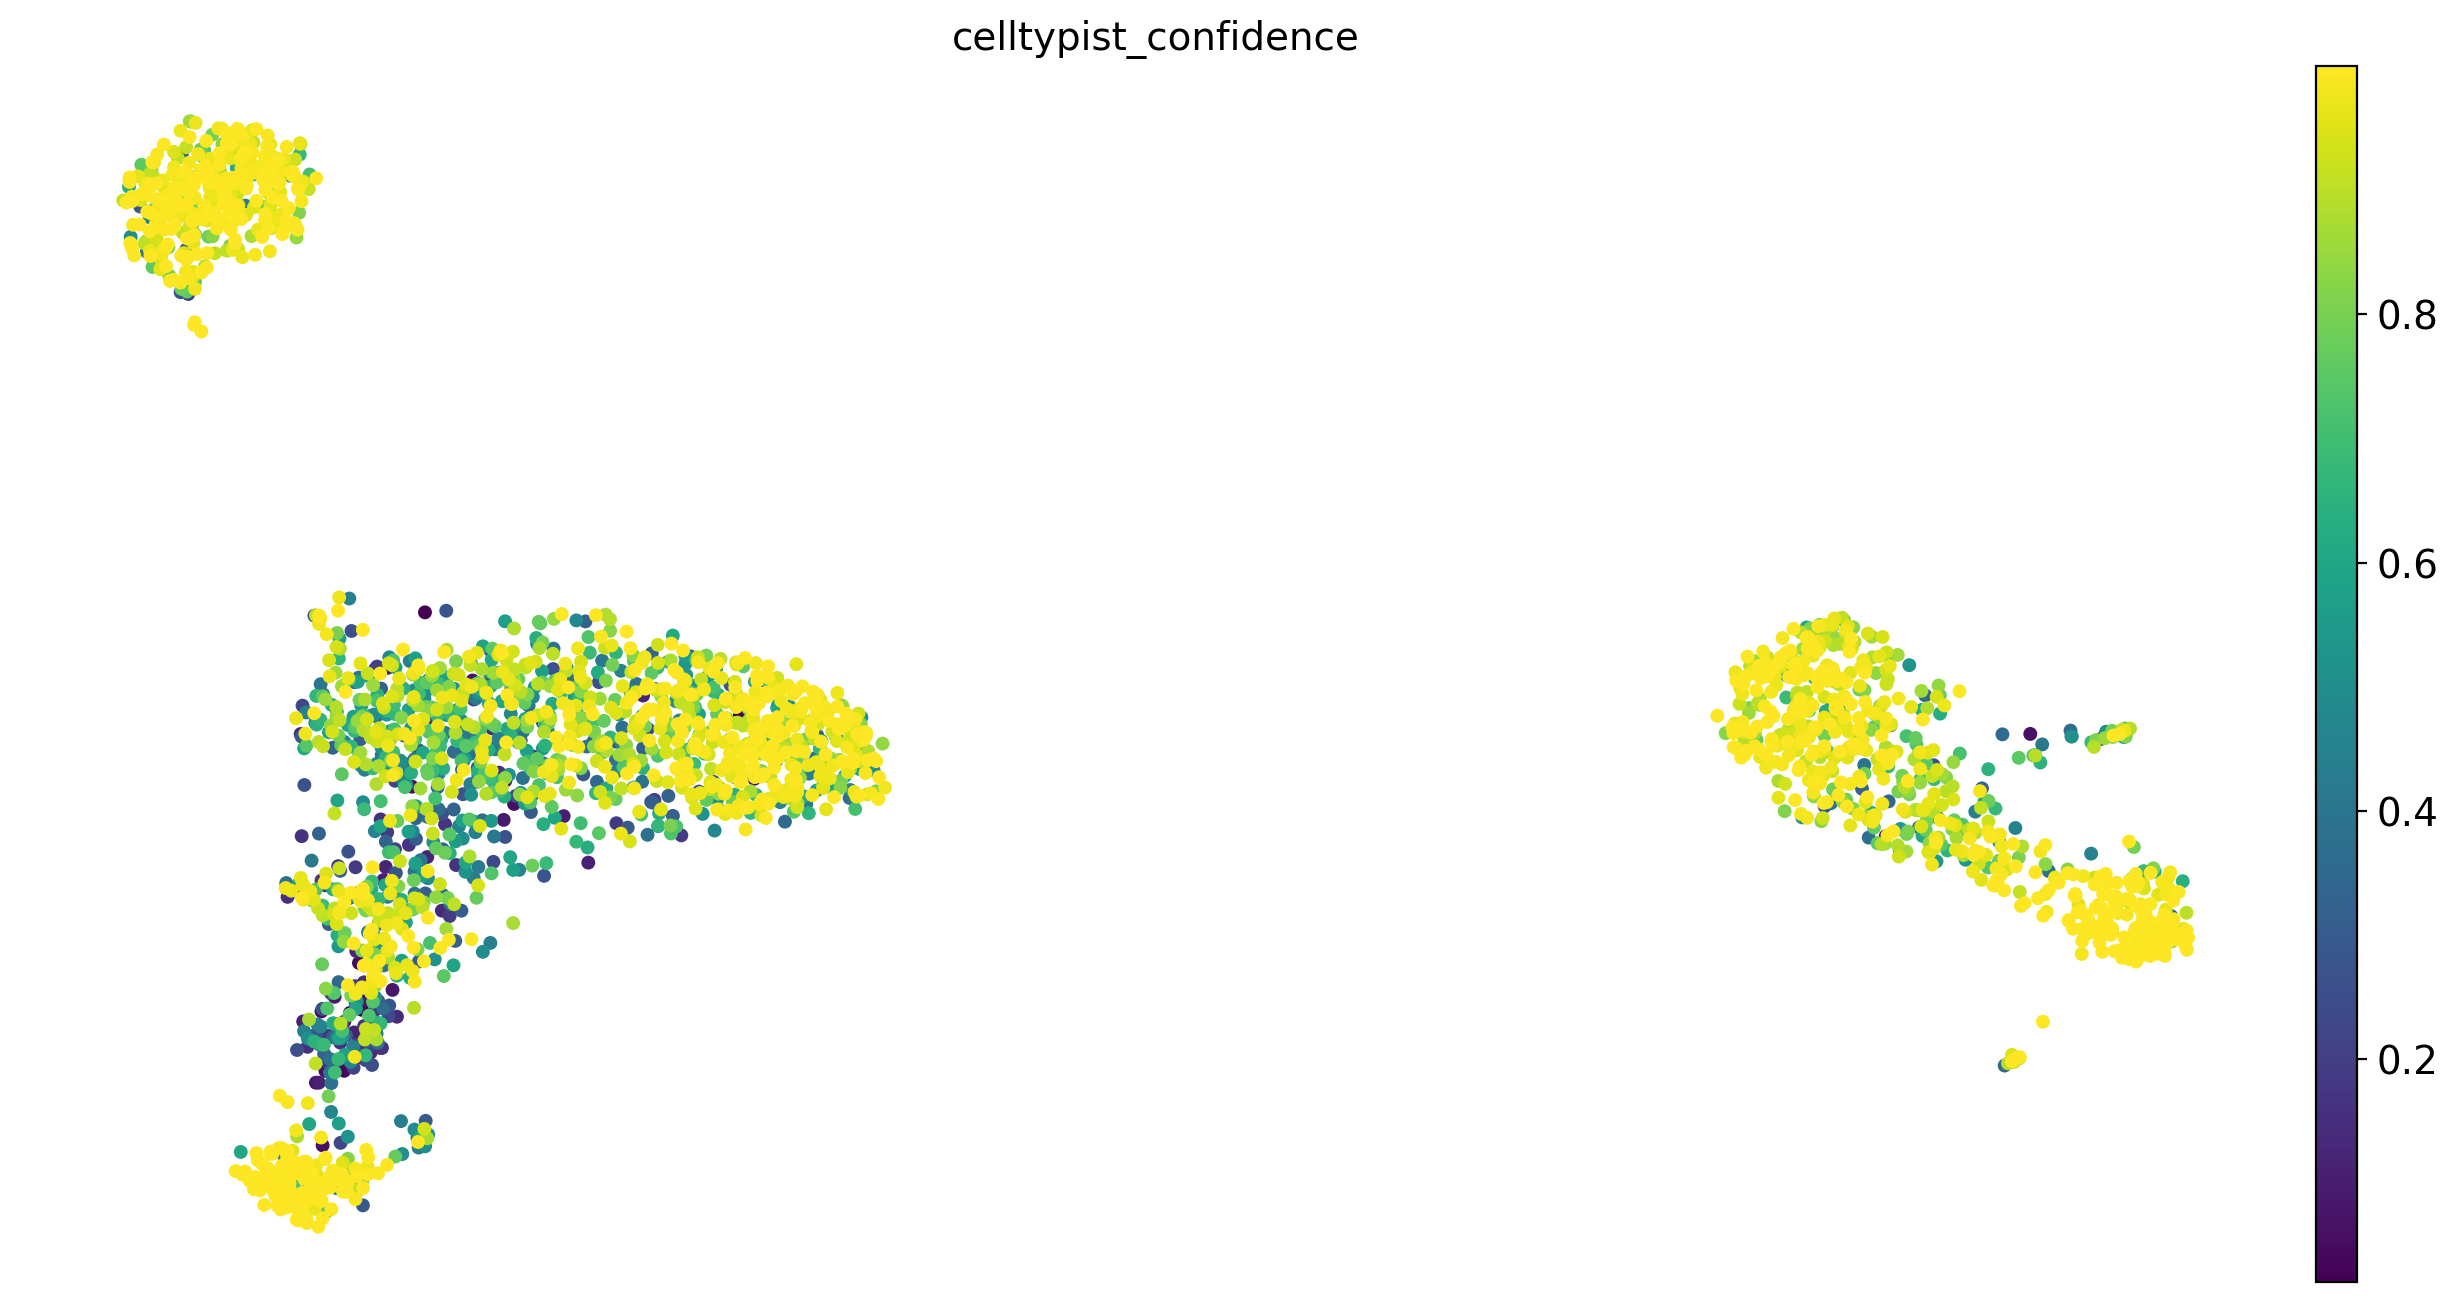

In [ ]:
# Получаем confidence для каждой клетки
adata.obs["celltypist_confidence"] = (
    prediction.probability_matrix
    .max(axis=1)
    .reindex(adata.obs_names)
    .astype(float)
)

# Строим UMAP
sc.pl.umap(
    adata,
    color="celltypist_confidence",
    cmap="viridis",
    size=100
)

In [ ]:
display(pd.crosstab(adata.obs['leiden_1.0'], adata.obs["celltypist"],
                    rownames=["Leiden"], colnames=["CellTypist"]))

CellTypist,B cells,CD16+ NK cells,CD16- NK cells,CD8a/a,Classical monocytes,Cycling T cells,DC,DC1,DC2,DC3,...,Tcm/Naive helper T cells,Tem/Effector helper T cells,Tem/Temra cytotoxic T cells,Tem/Trm cytotoxic T cells,Treg(diff),Trm cytotoxic T cells,Type 1 helper T cells,Type 17 helper T cells,gamma-delta T cells,pDC
Leiden,,,,,,,,,,,,,,,,,,,,,
0,2,0,0,0,0,0,1,0,0,0,...,271,169,0,0,1,2,1,5,0,0
1,4,0,1,0,0,0,1,0,0,0,...,342,10,0,5,0,0,0,0,0,0
2,1,0,1,0,342,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,8,0,1,0,1,1,0,0,0,...,21,8,17,102,2,8,2,0,1,0
4,328,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
5,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,141,2,0,0,0,0,0,0,0,...,0,0,2,0,0,0,0,0,0,0
7,0,0,0,0,48,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,2,0,14,1,8,1,...,0,0,0,0,0,0,0,0,0,1


---
## 4. Генные программы

`sc.tl.score_genes()` вычисляет для каждой клетки разность между средней экспрессией заданной ген ной сигнатуры и средней экспрессией контрольных генов, отобранных с учётом уровня экспрессии:

$$S(c)=\frac{1}{|G|}\sum_{g\in G}x_{cg} - \frac{1}{|G_0|}\sum_{h\in G_0}x_{ch}.$$

Здесь $G$ — целевая программа, $G_0$ — набор подобранных контрольных генов.

computing score 'cytotoxic_score'
    finished (0:00:00)


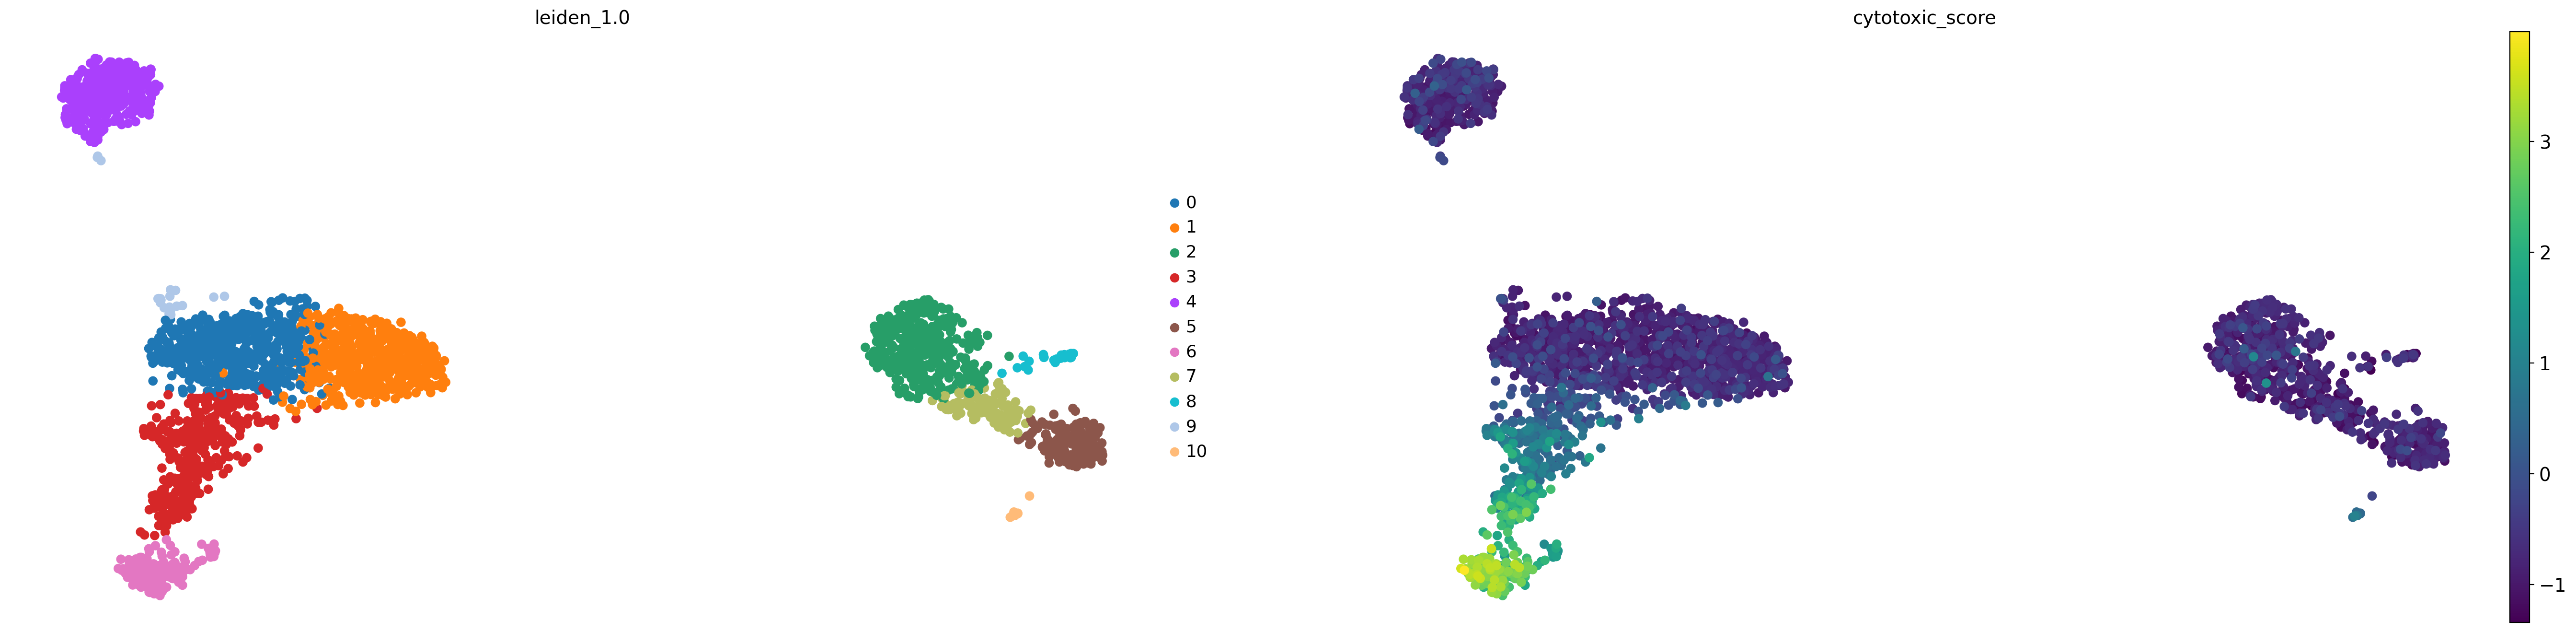

In [ ]:
cytotoxic_genes = [g for g in ["NKG7", "GNLY", "GZMB", "PRF1", "CCL5"]
                   if g in adata.var_names]

sc.tl.score_genes(
    adata,
    gene_list=cytotoxic_genes,
    score_name="cytotoxic_score",
    use_raw=False,
    random_state=42,
)
sc.pl.umap(adata, color=['leiden_1.0', "cytotoxic_score"], ncols=2, size=200)

In [ ]:
score_summary = (adata.obs.groupby('leiden_1.0', observed=True)["cytotoxic_score"]
                 .agg(["mean", "median", "count"])
                 .sort_values("mean", ascending=False))
display(score_summary)

,mean,median,count
leiden_1.0,,,
6,2.632246,2.718706,156
3,0.866440,0.759517,347
10,0.487299,0.476835,12
9,-0.654455,-0.816104,21
1,-0.755196,-0.843985,536
4,-0.793460,-0.874310,341
0,-0.801649,-0.898013,553
2,-0.808824,-0.858775,378
5,-0.900530,-0.910399,157


---
## 5. Сохранение результатов

In [ ]:
path_annotated = DATA_DIR / "pbmc3k_after_annotation.h5ad"
path_tcells = DATA_DIR / "pbmc3k_Tcells_subclustered.h5ad"
path_table = DATA_DIR / "pbmc3k_manual_cluster_labels.csv"

adata.write_h5ad(path_annotated, compression="gzip")
adata.write_h5ad(path_tcells, compression="gzip")
pd.DataFrame({"cluster": list(manual_annotations.keys()),
              "manual_cell_type": list(manual_annotations.values())}).to_csv(path_table, index=False)

print("Сохранено:")
for path in [path_annotated, path_tcells, path_table,
             DATA_DIR / "pbmc3k_markers_all.csv", DATA_DIR / "pbmc3k_markers_filtered.csv"]:
    print(" ", path, "(", round(path.stat().st_size / 1024**2, 2), "МБ)")

Сохранено:
  data/pbmc3k_after_annotation.h5ad ( 25.68 МБ)
  data/pbmc3k_Tcells_subclustered.h5ad ( 25.68 МБ)
  data/pbmc3k_manual_cluster_labels.csv ( 0.0 МБ)
  data/pbmc3k_markers_all.csv ( 15.26 МБ)
  data/pbmc3k_markers_filtered.csv ( 0.42 МБ)


## 8. **Итоговая цепочка анализа:**

`counts → QC → normalize/log1p → HVG → PCA → kNN → Leiden → Аннотация по маркерам  → Автоматическая аннотация (если возможна) → Аннотация по группе генов (score_genes) → субкластеризация → И так по кругу пока не найдем биологию`

![](after.jpg)

## 9. Самостоятельная + домашняя работа

**Задача:** самостоятельно провести полный анализ scRNA-seq данных: от контроля качества и фильтрации клеток до кластеризации, аннотации клеточных типов и анализа генных программ.

**Формат работы:** индивидуально или в парах. Можно выбрать любой открытый scRNA-seq датасет. Рекомендуется использовать данные, содержащие несколько различных клеточных популяций.

### Задание 1. Выбор данных и контроль качества (QC)

1. Найдите открытый scRNA-seq датасет и загрузите его в `AnnData`.
2. Кратко опишите выбранные данные:
   - Какие клетки или ткани исследовались?
   - Какой биологический вопрос изучали авторы?
   - Сколько клеток и генов содержится в датасете?
3. Рассчитайте основные показатели QC: `total_counts`, `n_genes_by_counts`, `pct_counts_mt`.
4. Постройте графики распределения этих показателей (violin plots, scatter plots).
5. Выберите пороги фильтрации и удалите клетки низкого качества, а также редко обнаруживаемые гены.
6. Покажите, сколько клеток и генов осталось после фильтрации.

**Обязательно объясните, почему выбрали именно такие пороги и какие клетки они позволяют исключить.**

### Задание 2. Нормализация и высоковариабельные гены (HVG)

1. Выполните нормализацию и логарифмирование экспрессии.
2. Найдите высоковариабельные гены с помощью `sc.pp.highly_variable_genes()`.
3. Постройте график HVG.
4. Покажите, сколько генов было выбрано.
5. Выведите 10 наиболее высоковариабельных генов и попробуйте выяснить, какие функции они выполняют.

**Вопрос:** зачем мы выбираем HVG и почему не обязательно использовать все гены для PCA и кластеризации?

### Задание 3. PCA и кластеризация

1. Выполните PCA, используя HVG.
2. Постройте график PCA и график объяснённой дисперсии (`sc.pl.pca_variance_ratio()`).
3. Постройте граф соседства клеток и вычислите UMAP.
4. Выполните кластеризацию Leiden с двумя различными значениями `resolution`, например 0.3 и 1.0.
5. Постройте два UMAP с результатами кластеризации.
6. Сравните количество и размеры получившихся кластеров.

**Вопросы:**
- Как изменение `resolution` влияет на число кластеров?
- Какие кластеры разделились при увеличении разрешения?
- Обязательно ли каждый получившийся кластер соответствует отдельному типу клеток?

### Задание 4. Ручная аннотация клеток

Выберите одно из двух разрешений Leiden для дальнейшей работы.

1. Найдите маркерные гены кластеров с помощью `sc.tl.rank_genes_groups()`.
2. Для каждого кластера рассмотрите наиболее высокоранжированные гены, их экспрессию и долю экспрессирующих клеток.
3. Найдите в литературе или специализированных базах известные маркеры предполагаемых клеточных типов.
4. Постройте `dotplot` и UMAP с экспрессией выбранных маркеров.
5. Присвойте каждому кластеру предполагаемый клеточный тип и сохраните результаты в `adata.obs["manual_cell_type"]`.

Составьте таблицу:

| Кластер | Предполагаемый клеточный тип | Маркерные гены | Обоснование |
|---|---|---|---|
| 0 | ... | ... | ... |
| 1 | ... | ... | ... |
| ... | ... | ... | ... |

**Важно:** если клеточный тип невозможно уверенно определить, используйте `Unknown` или более общее название популяции. Необязательно каждому кластеру присваивать уникальный клеточный тип.

### Задание 5. Автоматическая аннотация

1. Найдите инструмент автоматической аннотации клеточных типов или используйте `CellTypist`.
2. Выберите подходящую референсную модель для вашего датасета.
3. Выполните автоматическую аннотацию клеток.
4. Постройте UMAP с результатами автоматической аннотации.
5. Сравните результаты с вашей ручной аннотацией.

Для сравнения постройте таблицу сопряжённости (`pd.crosstab()`), показывающую, какие автоматические аннотации соответствуют каждому кластеру и каждому типу из ручной аннотации.

**Вопросы:**
- Для каких кластеров ручная и автоматическая аннотации совпали?
- Где наблюдаются расхождения?
- С чем они могут быть связаны?
- Какую аннотацию вы считаете более обоснованной и почему?

Если выбранный инструмент не поддерживает ваш вид или ткань, объясните ограничение и попробуйте найти подходящую альтернативу.

### Задание 6. Субкластеризация

Выберите один из полученных кластеров, который потенциально содержит несколько клеточных подтипов или функциональных состояний.

1. Создайте отдельный `AnnData`, содержащий только клетки выбранного кластера.
2. Повторите необходимые этапы анализа для этого подмножества: отбор HVG, PCA, построение графа соседства, UMAP и Leiden.
3. Постройте UMAP полученных субкластеров.
4. Найдите маркерные гены новых субкластеров.
5. Попробуйте определить более узкие клеточные типы или состояния на основании маркеров.

**Вопросы:**
- Удалось ли разделить исходную популяцию на биологически интерпретируемые субпопуляции?
- Какие гены отличают новые субкластеры?
- Почему эти различия могли быть незаметны при первоначальной кластеризации всех клеток?

Если убедительных субпопуляций обнаружить не удалось, объясните возможные причины.

### Задание 7. Генные программы (Gene Scores)

Выберите **три набора генов**, соответствующих различным биологическим функциям или клеточным состояниям.

Например:
- Цитотоксичность: `NKG7`, `PRF1`, `GZMB`, `GNLY`.
- Интерфероновый ответ: `ISG15`, `IFIT1`, `MX1`, `IFI6`.
- Пролиферация: `MKI67`, `TOP2A`, `PCNA`, `TYMS`.

Можно использовать другие программы, более подходящие для выбранных данных. Укажите, откуда взяты наборы генов.

1. Рассчитайте оценки всех трёх программ с помощью `sc.tl.score_genes()`.
2. Постройте UMAP, раскрашенные по значениям каждого score.
3. Постройте violin plots распределения scores по аннотированным клеточным типам.
4. Определите, в каких клеточных популяциях каждая программа выражена сильнее всего.
5. Сравните полученные результаты с аннотацией клеточных типов.

**Главный вопрос:** как информацию о генных программах можно использовать для уточнения ручной аннотации клеток?

Приведите конкретные примеры из своих данных: какие программы помогают различать клеточные типы, подтипы или функциональные состояния?

Помните, что высокий gene score отражает относительную экспрессию сигнатуры, но сам по себе не доказывает выполнение биологической функции.

### Задание 8. Итоговые результаты и выводы

Подготовьте итоговую визуализацию и краткое заключение.

В работе должны присутствовать:

- UMAP с исходной кластеризацией при двух разрешениях.
- UMAP с ручной аннотацией клеточных типов.
- UMAP с автоматической аннотацией.
- Dotplot основных маркерных генов.
- UMAP субкластеров выбранной популяции.
- Три UMAP с оценками генных программ.
- Сравнение ручной и автоматической аннотации.

**Ответьте в заключении:**

1. Какие основные клеточные популяции удалось обнаружить?
2. Какие маркерные гены позволили их идентифицировать?
3. Насколько согласуются ручная и автоматическая аннотации?
4. Что удалось обнаружить при субкластеризации?
5. Какие дополнительные сведения о клетках дали генные программы?

---

### Что сдавать

**Один Jupyter Notebook (`.ipynb`)**, содержащий весь воспроизводимый анализ, графики и пояснения к результатам.

В начале ноутбука укажите название датасета, ссылку на источник и участников работы.

Каждый этап должен сопровождаться кратким объяснением: **что было сделано, зачем и какой результат получен**.

Допускается работа в парах (не более двух человек). В этом случае сдаётся один общий ноутбук с указанием обоих участников.

# Самостоятельная и домашняя работа

## Задание 1. Выбор данных и контроль качества

Для анализа я выбрала открытый датасет PBMC 4k от 10x Genomics. В нём представлены мононуклеарные клетки периферической крови здорового донора. Цель анализа: определить основные иммунные клеточные популяции и различия в экспрессии генов между ними.

Источник: [10x Genomics PBMC 4k](https://www.10xgenomics.com/datasets/4-k-pbm-cs-from-a-healthy-donor-2-standard-1-2-0)

In [7]:
from pathlib import Path

PBMC4K_DIR = Path("pbmc4k_data")
PBMC4K_DIR.mkdir(exist_ok=True)

url = "https://cf.10xgenomics.com/samples/cell-exp/2.1.0/pbmc4k/pbmc4k_filtered_gene_bc_matrices.tar.gz"

!wget -q --show-progress --tries=5 -O pbmc4k.tar.gz "$url"
!tar -xzf pbmc4k.tar.gz -C pbmc4k_data

pbmc4k.tar.gz       100%[===================>]  17.57M  --.-KB/s    in 0.1s    


In [8]:
raw_dir_hw = PBMC4K_DIR / "filtered_gene_bc_matrices" / "GRCh38"

adata_hw = sc.read_10x_mtx(
    raw_dir_hw,
    var_names="gene_symbols",
    make_unique=True
)

adata_hw.var_names_make_unique()

print(adata_hw)
print("Клеток до QC:", adata_hw.n_obs)
print("Генов до QC:", adata_hw.n_vars)

AnnData object with n_obs × n_vars = 4340 × 33694
    var: 'gene_ids'
Клеток до QC: 4340
Генов до QC: 33694


In [9]:
adata_hw.var["mt"] = adata_hw.var_names.str.startswith("MT-")

sc.pp.calculate_qc_metrics(
    adata_hw,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

adata_hw.obs[
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"]
].describe(percentiles=[0.01, 0.05, 0.95, 0.99])

,total_counts,n_genes_by_counts,pct_counts_mt
count,4340.000000,4340.000000,4340.000000
mean,4349.037598,1319.745392,3.215936
std,2352.223877,463.436009,1.593086
min,1386.000000,498.000000,0.162955
1%,1505.390000,610.390000,1.081852
5%,1907.800000,753.950000,1.556277
50%,3866.500000,1235.000000,2.846002
95%,8386.050000,2213.150000,5.894281
99%,13938.530000,3095.830000,7.917891
max,48443.000000,5251.000000,33.468765


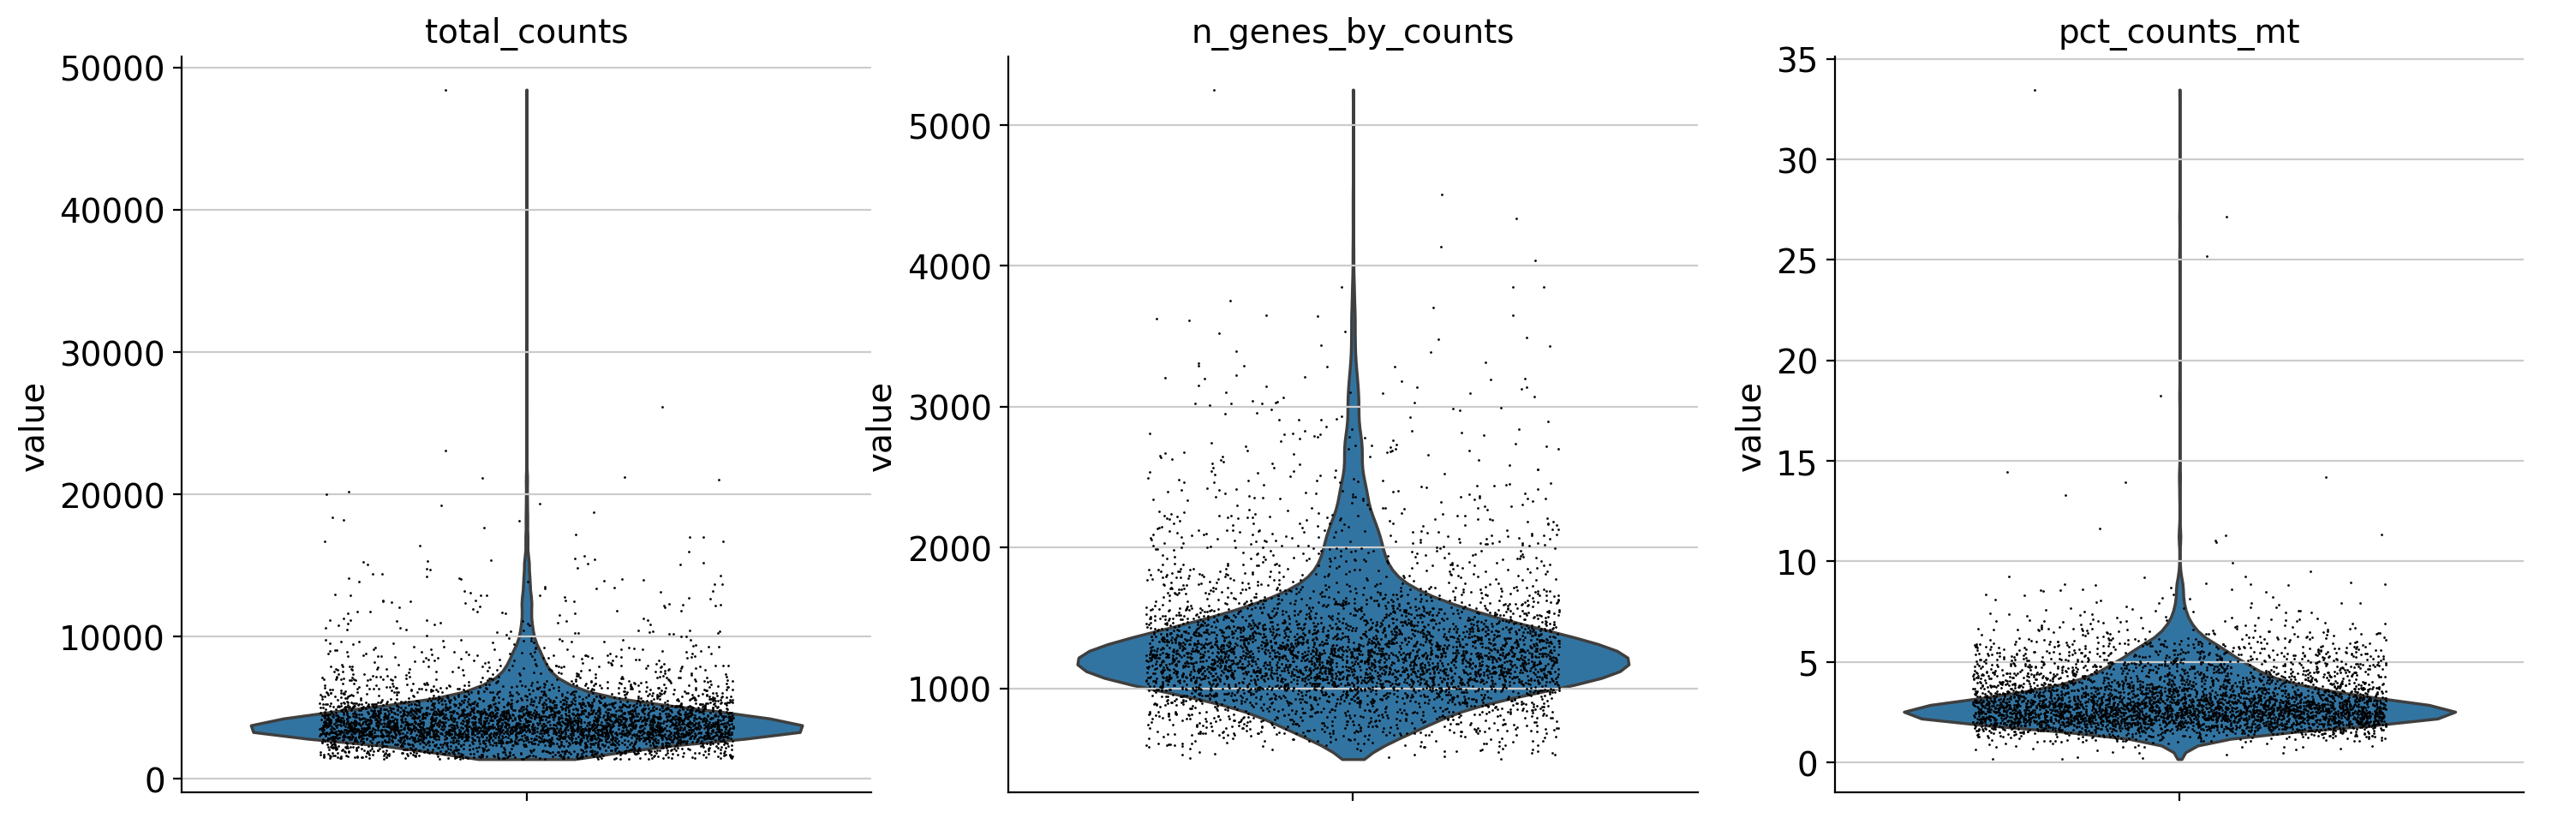

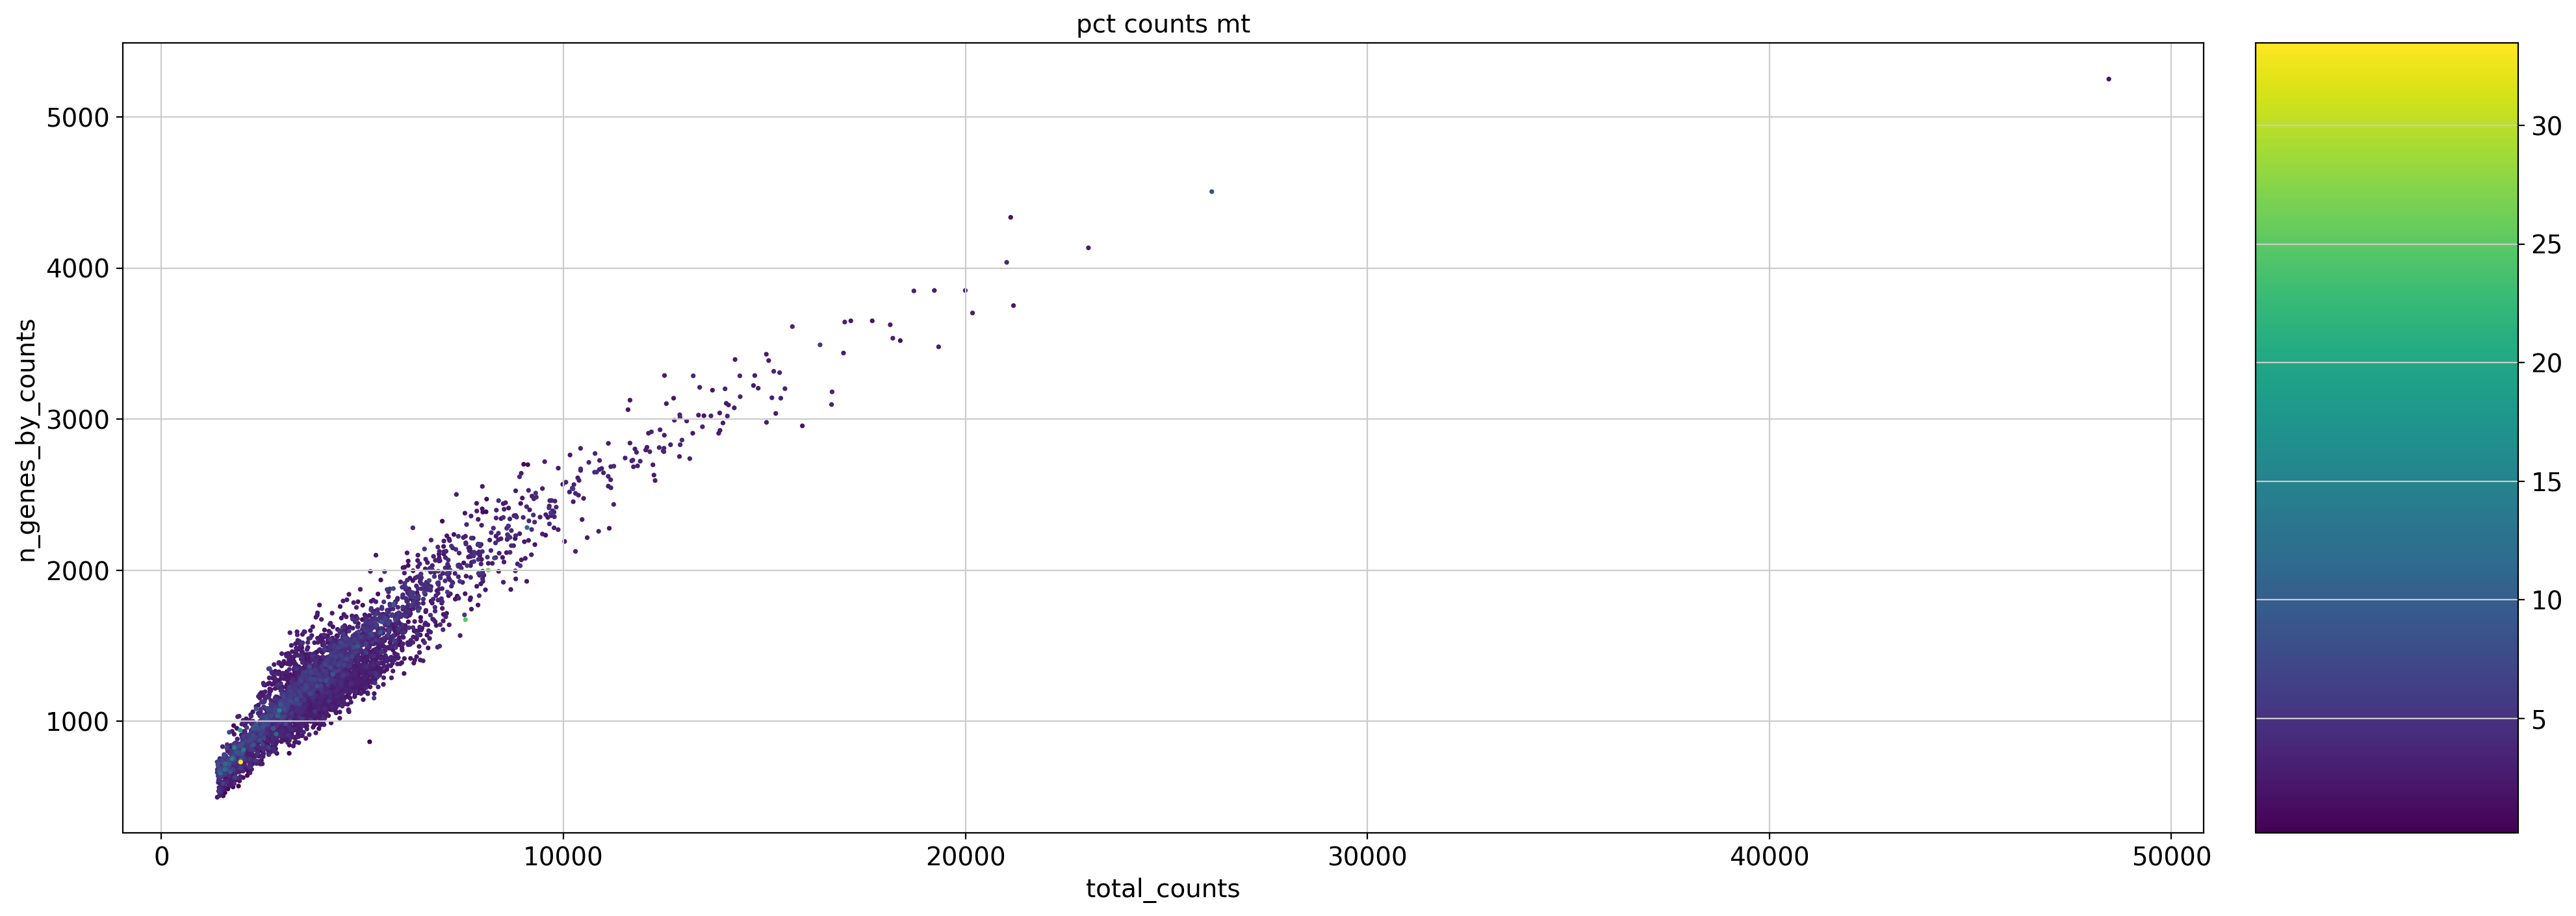

In [10]:
sc.pl.violin(
    adata_hw,
    ["total_counts", "n_genes_by_counts", "pct_counts_mt"],
    jitter=0.3,
    multi_panel=True
)

sc.pl.scatter(
    adata_hw,
    x="total_counts",
    y="n_genes_by_counts",
    color="pct_counts_mt"
)

По распределениям основная масса клеток находится примерно между 1500–14000 UMI, 600–3000 генов и ниже 8% митохондриальных счётчиков. Значения за этими пределами выглядят как выбросы.

In [11]:
cells_before = adata_hw.n_obs
genes_before = adata_hw.n_vars

adata_hw = adata_hw[
    (adata_hw.obs["total_counts"] >= 1500) &
    (adata_hw.obs["total_counts"] < 15000) &
    (adata_hw.obs["n_genes_by_counts"] >= 600) &
    (adata_hw.obs["n_genes_by_counts"] < 3000) &
    (adata_hw.obs["pct_counts_mt"] < 8)
].copy()

sc.pp.filter_genes(adata_hw, min_cells=3)

print("Клеток до QC:", cells_before)
print("Клеток после QC:", adata_hw.n_obs)
print("Удалено клеток:", cells_before - adata_hw.n_obs)

print("Генов до QC:", genes_before)
print("Генов после QC:", adata_hw.n_vars)

filtered out 17239 genes that are detected in less than 3 cells
Клеток до QC: 4340
Клеток после QC: 4179
Удалено клеток: 161
Генов до QC: 33694
Генов после QC: 16455


До фильтрации в датасете было 4340 клеток и 33694 гена. Я оставила клетки с 1500–15000 UMI, 600–3000 обнаруженными генами и долей митохондриальных счётчиков меньше 8%. Так удаляются клетки с небольшим количеством материала, повреждённые клетки и возможные двойные капли. Также я убрала гены, обнаруженные меньше чем в трёх клетках. После QC осталось 4179 клеток и 16455 генов.

## Задание 2. Нормализация и высоковариабельные гены

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
Количество HVG: 2000


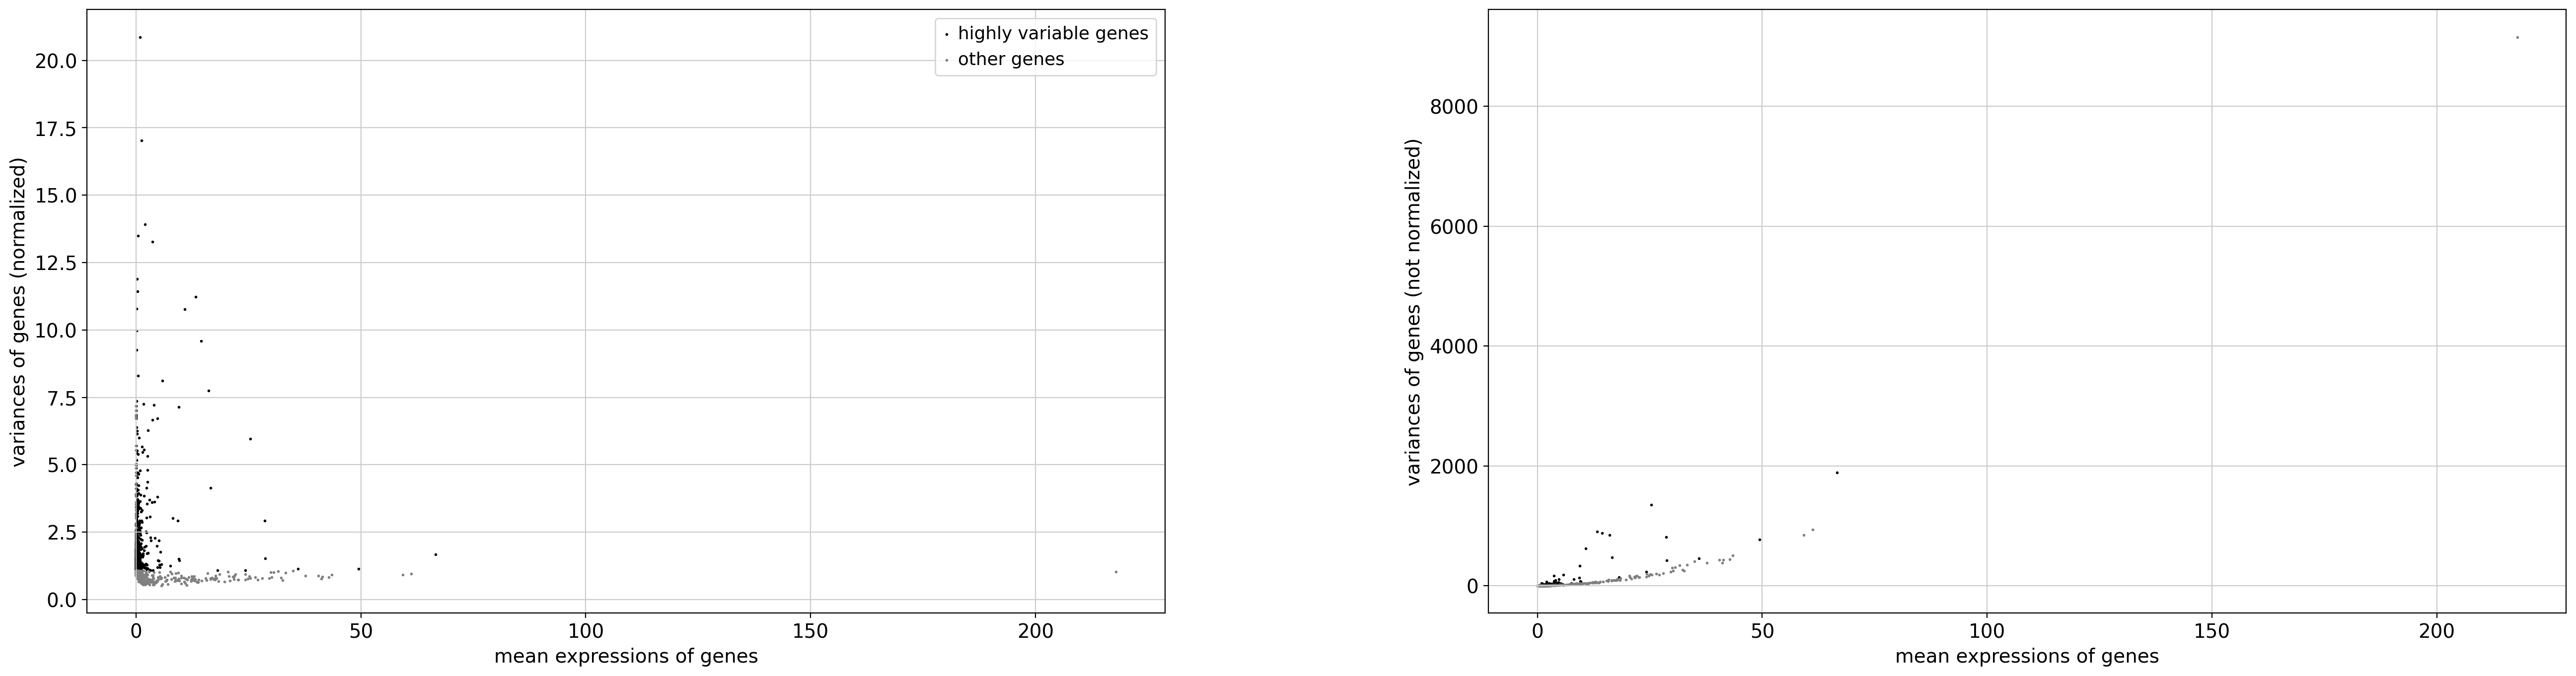

In [12]:

adata_hw.layers["counts"] = adata_hw.X.copy()

sc.pp.normalize_total(adata_hw, target_sum=1e4)
sc.pp.log1p(adata_hw)

sc.pp.highly_variable_genes(
    adata_hw,
    layer="counts",
    flavor="seurat_v3",
    n_top_genes=2000
)


adata_hw.raw = adata_hw

print("Количество HVG:", adata_hw.var["highly_variable"].sum())

sc.pl.highly_variable_genes(adata_hw)

In [13]:
top10_hvg = (
    adata_hw.var
    .sort_values("highly_variable_rank")
    .head(10)[
        ["highly_variable_rank", "means", "variances", "variances_norm"]
    ]
)

display(top10_hvg)

,highly_variable_rank,means,variances,variances_norm
IGLC3,0.0,0.943049,42.119781,20.865028
IGLC2,1.0,1.167265,36.476803,17.037433
GNLY,2.0,2.046183,70.395425,13.918407
GZMB,3.0,0.471165,8.773881,13.500547
IGKC,4.0,3.704475,169.792730,13.283300
FCER1A,5.0,0.223738,3.245525,11.894225
JCHAIN,6.0,0.335487,10.735196,11.432407
S100A9,7.0,13.275664,900.607572,11.239541
AL928768.3,8.0,0.080163,1.281509,10.787652
S100A8,9.0,10.785355,622.462055,10.773018


Было выбрано 2000 высоковариабельных генов (HVG).

Функции первых 10 HVG:

1. IGLC3 участвует в образовании константной части лямбда-цепи иммуноглобулинов. Связан с B-клетками и продукцией антител.
2. IGLC2 также кодирует константную часть лямбда-цепи иммуноглобулинов и участвует в гуморальном иммунном ответе.
3. GNLY кодирует гранулизин, который содержится в гранулах NK-клеток и цитотоксических T-клеток и участвует в уничтожении клеток-мишеней.
4. GZMB кодирует гранзим B, запускающий гибель клеток-мишеней. Характерен для NK-клеток и цитотоксических T-клеток.
5. IGKC кодирует константную часть каппа-цепи иммуноглобулинов. Является признаком B-клеток и плазматических клеток.
6. FCER1A кодирует альфа-субъединицу высокоаффинного рецептора IgE. В PBMC часто используется как маркер дендритных клеток.
7. JCHAIN участвует в объединении молекул IgM и IgA. Характерен для антителосекретирующих плазматических клеток.
8. S100A9 белок врождённого иммунитета и воспаления, характерный главным образом для моноцитов.
9. AL928768.3 слабо охарактеризованный транскрипт, точная биологическая функция которого пока не установлена.
10. S100A8 воспалительный белок, характерный для моноцитов и других миелоидных клеток. Вместе с S100A9 образует комплекс кальпротектин.

HVG используются потому, что их экспрессия сильнее всего различается между клетками, поэтому они содержат больше информации о различиях между клеточными типами. Использование всех генов добавило бы много слабо изменяющихся и шумовых признаков, а также увеличило бы время вычислений. При этом высоко экспрессирующийся ген не обязательно является высоковариабельным, тк важно не среднее значение экспрессии, а различия между клетками.

## Задание 3. PCA и кластеризация

In [14]:

adata_hw = adata_hw[:, adata_hw.var["highly_variable"]].copy()


sc.pp.scale(adata_hw, max_value=10)
sc.tl.pca(
    adata_hw,
    n_comps=50,
    svd_solver="arpack",
    random_state=42
)

print("Размер матрицы после выбора HVG:", adata_hw.shape)

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


computing PCA
    with n_comps=50
    finished (0:00:05)
Размер матрицы после выбора HVG: (4179, 2000)


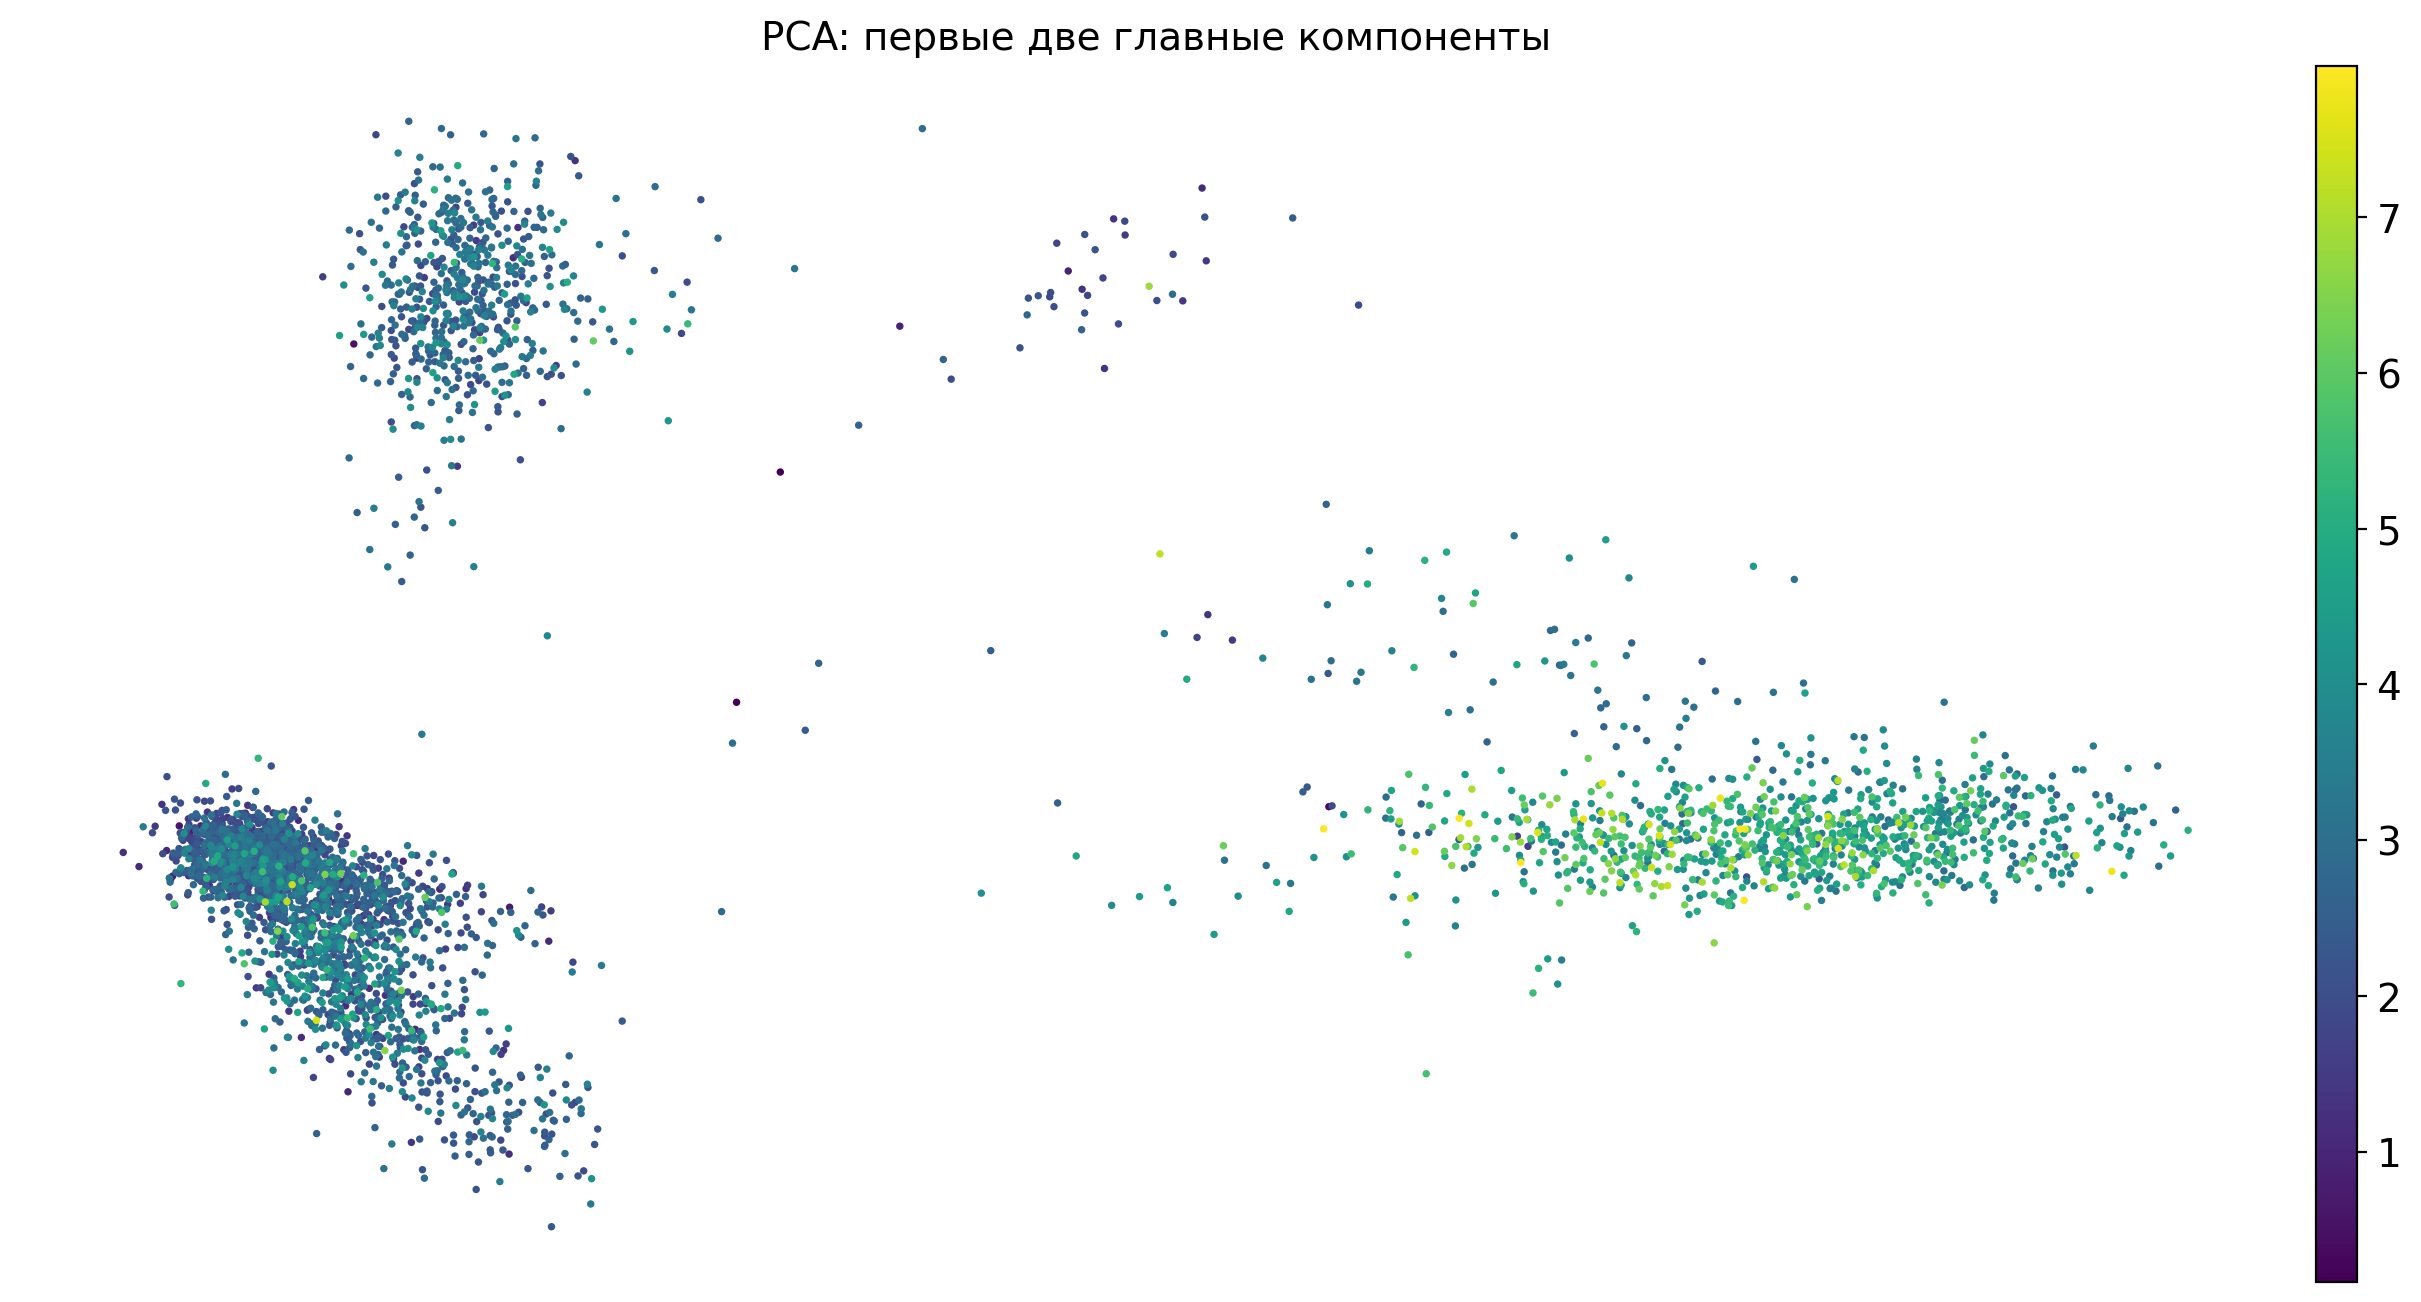

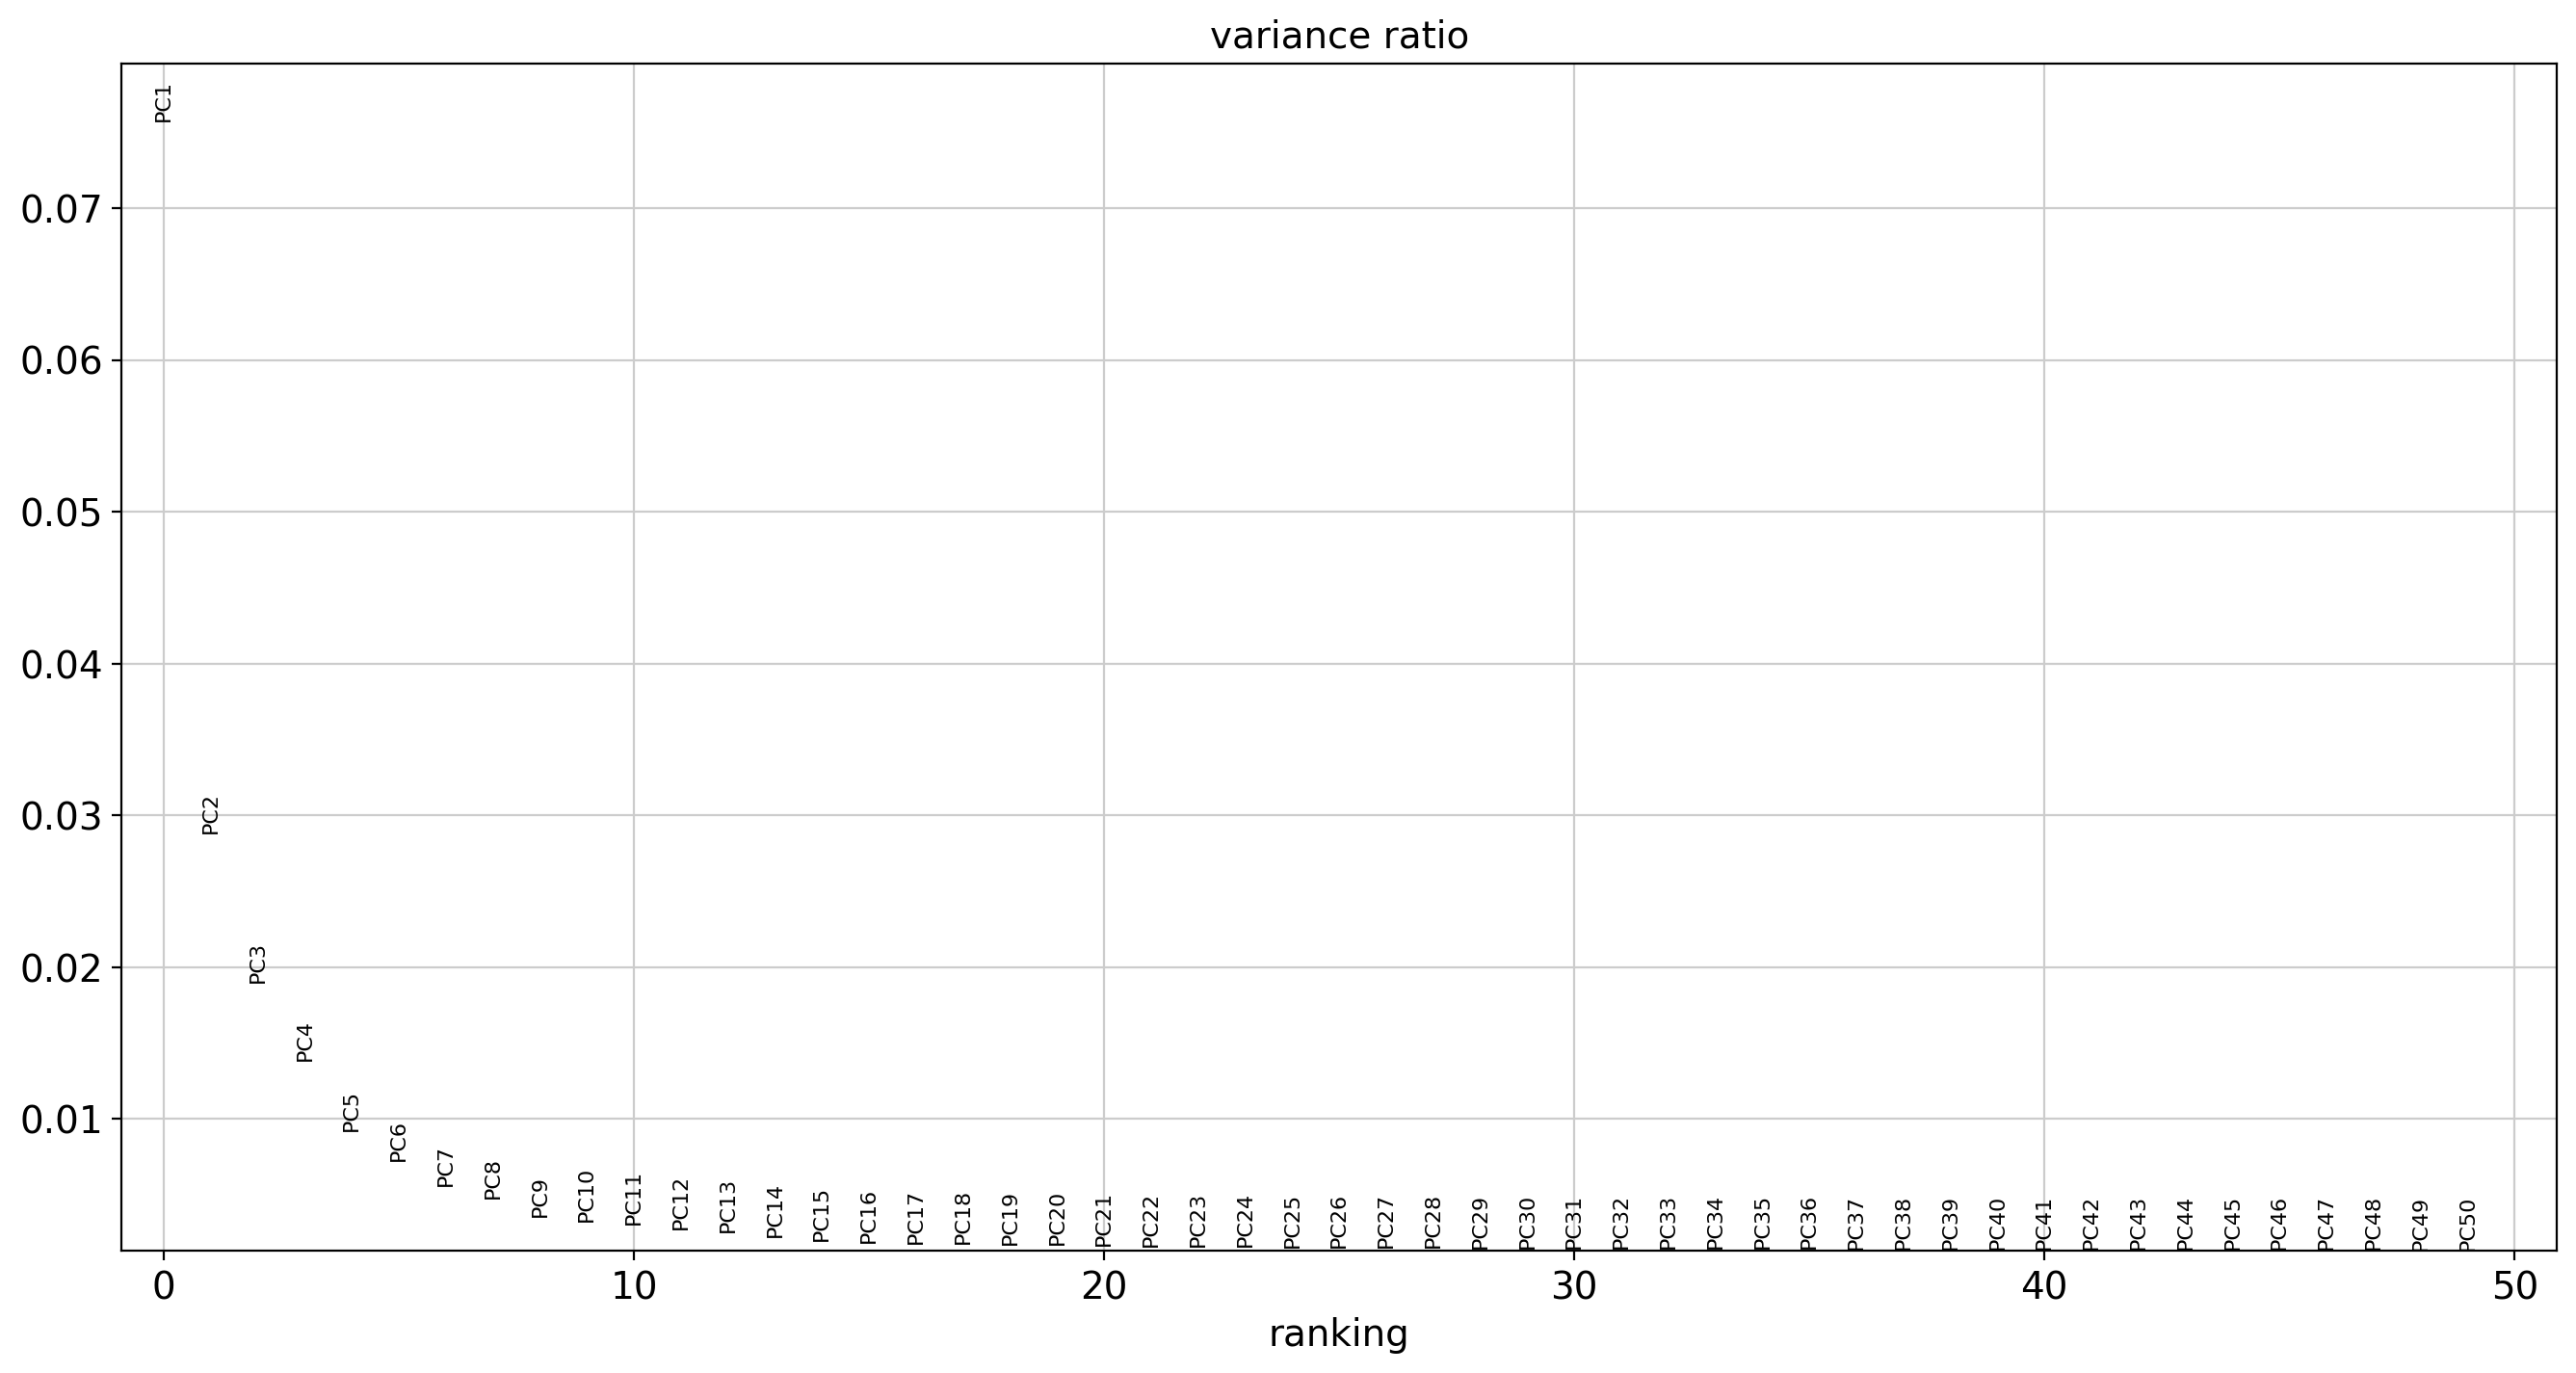

In [15]:

sc.pl.pca(
    adata_hw,
    color="pct_counts_mt",
    title="PCA: первые две главные компоненты"
)


sc.pl.pca_variance_ratio(
    adata_hw,
    n_pcs=50,
    log=False
)

In [16]:
variance_ratio = adata_hw.uns["pca"]["variance_ratio"]

pca_table = pd.DataFrame({
    "PC": np.arange(1, len(variance_ratio) + 1),
    "Дисперсия, %": variance_ratio * 100,
    "Накопленная дисперсия, %": np.cumsum(variance_ratio) * 100
})

display(pca_table.head(30))

,PC,"Дисперсия, %","Накопленная дисперсия, %"
0,1,7.572052,7.572052
1,2,2.884286,10.456338
2,3,1.900157,12.356495
3,4,1.381668,13.738163
4,5,0.923409,14.661572
5,6,0.722044,15.383617
6,7,0.560334,15.943951
7,8,0.477641,16.421592
8,9,0.353941,16.775533
9,10,0.324957,17.100490


Первая главная компонента объясняет 7,57% различий между клетками, а вторая 2,88%. Вместе они объясняют 10,46%. На графике видно несколько отдельных групп клеток, значит PCA смог показать различия в их экспрессии генов.

Самый заметный спад наблюдается примерно до PC8–PC10. Для дальнейшего анализа я выбрала 30 главных компонент, чтобы сохранить не только основные, но и более слабые различия между клетками. Вместе они объясняют около 20,8% дисперсии.

In [17]:

sc.pp.neighbors(
    adata_hw,
    n_neighbors=15,
    n_pcs=30,
    random_state=42
)

sc.tl.umap(
    adata_hw,
    random_state=42
)

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:00)
computing UMAP
    finished (0:00:10)


In [18]:

sc.tl.leiden(
    adata_hw,
    resolution=0.3,
    key_added="leiden_03",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=42
)


sc.tl.leiden(
    adata_hw,
    resolution=1.0,
    key_added="leiden_10",
    flavor="igraph",
    n_iterations=2,
    directed=False,
    random_state=42
)

print("Количество кластеров при resolution=0.3:",
      adata_hw.obs["leiden_03"].nunique())

print("Количество кластеров при resolution=1.0:",
      adata_hw.obs["leiden_10"].nunique())

running Leiden clustering
    finished (0:00:00)
running Leiden clustering
    finished (0:00:00)
Количество кластеров при resolution=0.3: 10
Количество кластеров при resolution=1.0: 14


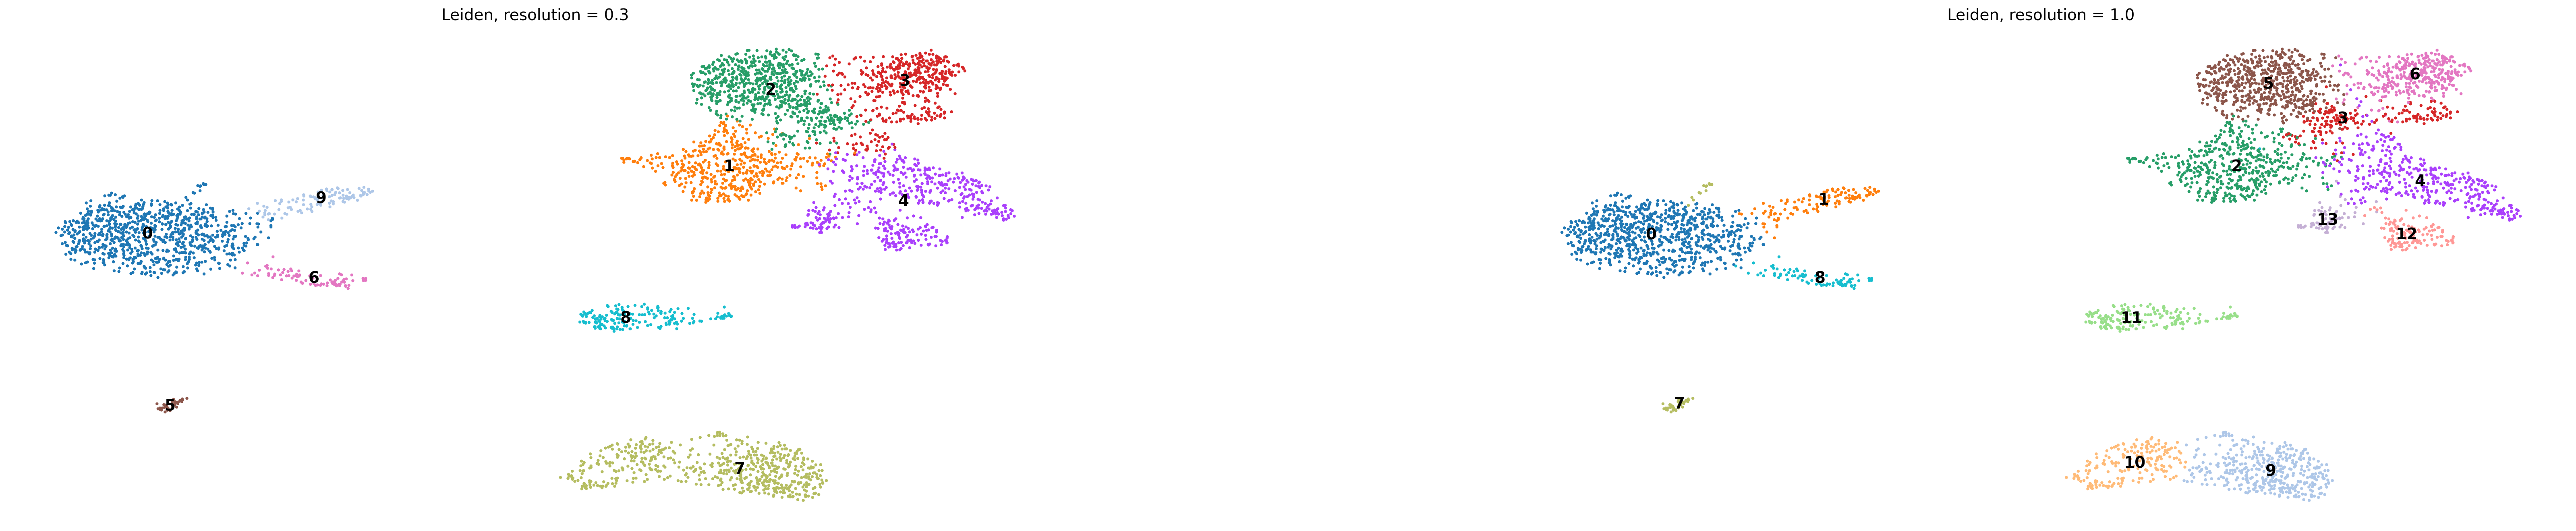

In [19]:
sc.pl.umap(
    adata_hw,
    color=["leiden_03", "leiden_10"],
    title=[
        "Leiden, resolution = 0.3",
        "Leiden, resolution = 1.0"
    ],
    legend_loc="on data",
    frameon=False,
    wspace=0.3
)

In [20]:
print("Размеры кластеров, resolution = 0.3:")
display(
    adata_hw.obs["leiden_03"]
    .value_counts()
    .sort_index()
    .to_frame("Количество клеток")
)

print("Размеры кластеров, resolution = 1.0:")
display(
    adata_hw.obs["leiden_10"]
    .value_counts()
    .sort_index()
    .to_frame("Количество клеток")
)

print("Какие кластеры разделились:")
cluster_comparison = pd.crosstab(
    adata_hw.obs["leiden_03"],
    adata_hw.obs["leiden_10"]
)

display(cluster_comparison)

Размеры кластеров, resolution = 0.3:


,Количество клеток
leiden_03,
0,899
1,483
2,763
3,486
4,530
5,37
6,83
7,600
8,188


Размеры кластеров, resolution = 1.0:


,Количество клеток
leiden_10,
0,872
1,124
2,487
3,193
4,387
5,634
6,361
7,49
8,85


Какие кластеры разделились:


leiden_10,0,1,2,3,4,5,6,7,8,9,10,11,12,13
leiden_03,,,,,,,,,,,,,,
0,872,14,0,0,0,0,0,12,1,0,0,0,0,0
1,0,0,474,2,6,0,0,0,1,0,0,0,0,0
2,0,0,13,121,1,627,1,0,0,0,0,0,0,0
3,0,0,0,68,51,7,360,0,0,0,0,0,0,0
4,0,0,0,2,329,0,0,0,0,0,0,0,122,77
5,0,0,0,0,0,0,0,37,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,83,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,412,188,0,0,0
8,0,0,0,0,0,0,0,0,0,0,0,188,0,0


При resolution = 0.3 получилось 10 кластеров, а при resolution = 1.0 14 кластеров. При увеличении resolution клетки разделяются на более мелкие группы.

Сильнее всего разделились кластеры 2, 3, 4 и 7. Например, кластер 7 разделился на кластеры 9 и 10, а кластер 4 на кластеры 4, 12 и 13. Некоторые части соседних кластеров также объединились по-другому, потому что лейден заново выполняет кластеризацию для каждого значения resolution.

Для дальнейшего анализа я выбрала resolution = 0.3. При нём получено 10 достаточно крупных и хорошо разделённых кластеров. Более подробное разделение одной из популяций будет выполнено позже при субкластеризации.

Не каждый кластер обязательно соответствует отдельному типу клеток. Один клеточный тип может разделяться на несколько кластеров из-за разных функциональных состояний, а в одном кластере могут находиться близкие клеточные подтипы.

## Задание 4. Ручная аннотация клеток

Для дальнейшей работы было выбрано разбиение Leiden с resolution = 0.3. При таком значении получилось 10 достаточно крупных кластеров. Далее для каждого кластера будут найдены маркерные гены, на основании которых клеткам будут присвоены предполагаемые типы.

ranking genes
    finished (0:00:25)




In [21]:
sc.tl.rank_genes_groups(
    adata_hw,
    groupby="leiden_03",
    method="wilcoxon",
    use_raw=True,
    pts=True,
    key_added="markers_leiden_03"
)

sc.pl.rank_genes_groups(
    adata_hw,
    key="markers_leiden_03",
    n_genes=10,
    sharey=False
)

In [22]:
markers_hw = sc.get.rank_genes_groups_df(
    adata_hw,
    group=None,
    key="markers_leiden_03"
)

top_markers_hw = markers_hw.groupby(
    "group",
    observed=True
).head(10)

display(
    top_markers_hw[
        [
            "group",
            "names",
            "logfoldchanges",
            "pvals_adj",
            "pct_nz_group",
            "pct_nz_reference"
        ]
    ]
)

,group,names,logfoldchanges,pvals_adj,pct_nz_group,pct_nz_reference
0,0,LYZ,6.353149,0.000000e+00,1.000000,0.537805
1,0,S100A8,6.190556,0.000000e+00,0.997775,0.504573
2,0,S100A9,5.956076,0.000000e+00,0.995551,0.604573
3,0,FTL,3.149153,0.000000e+00,1.000000,0.995122
4,0,TYROBP,5.151200,0.000000e+00,0.998888,0.350610
...,...,...,...,...,...,...
148100,9,MS4A7,5.113246,1.064286e-57,0.972727,0.119931
148101,9,PSAP,3.465785,1.903609e-57,1.000000,0.591546
148102,9,FTH1,2.422785,4.964671e-57,1.000000,0.992627
148103,9,LINC01272,4.976926,5.715946e-57,0.972727,0.113296
